# Klasifikasi Tutupan Lahan Jawa Timur

Notebook ini mengklasifikasikan citra Sentinel-2 menjadi lima kelas: **Hutan, Perairan, Lahan Pertanian, Bangunan, dan Mangrove**.

Fitur model terdiri dari band B2, B3, B4, B5, B8, B8A, B11 serta indeks NDVI, NDMI, MVI, REMI, MNDWI, NDRE, dan EVI. Model Random Forest, SVM, dan Decision Tree dilatih dan dibandingkan menggunakan sampel berlabel. Model Random Forest digunakan untuk menghasilkan peta klasifikasi.

Berkas masukan berada di folder `data` atau di folder yang sama dengan notebook. Hasil disimpan di `hasil_klasifikasi`.


## Impor pustaka dan penyiapan direktori

Sel ini memuat pustaka analisis, menentukan folder data, dan membuat folder untuk hasil serta berkas sementara.


In [1]:
from pathlib import Path
import os, json, glob, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import rasterio
from rasterio.warp import reproject, Resampling
from rasterio.features import shapes
import geopandas as gpd
from IPython.display import display
from rasterio.warp import transform_bounds
import matplotlib.colors as mcolors
from folium import raster_layers, Element
import folium
from shapely.geometry import shape
warnings.filterwarnings("ignore")
# Tentukan folder proyek.
try:
    PROJECT_DIR = Path(__file__).resolve().parent
except NameError:
    PROJECT_DIR = Path.cwd()
# Gunakan folder data jika berkas sumber berada di sana.
if not (PROJECT_DIR / "B02_gabungan.tiff").exists() and (PROJECT_DIR / "data" / "B02_gabungan.tiff").exists():
    PROJECT_DIR = PROJECT_DIR / "data"
DATA_DIR = PROJECT_DIR
OUTPUT_DIR = DATA_DIR / "hasil_klasifikasi"
TEMP_DIR = DATA_DIR / "data_klasifikasi"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
TEMP_DIR.mkdir(parents=True, exist_ok=True)
print("Folder data:", DATA_DIR)
print("Folder hasil:", OUTPUT_DIR)

Folder data: c:\Users\LENOVO\PSD\pertemuan_6\data
Folder hasil: c:\Users\LENOVO\PSD\pertemuan_6\data\hasil_klasifikasi


In [2]:
# Tampilkan berkas sumber yang tersedia.
print("Direktori data:", DATA_DIR.resolve())
files = sorted(p for p in DATA_DIR.iterdir() if p.is_file())
print(f"Jumlah file pada direktori data: {len(files)}")
for p in files:
    print(f"{p.name} ({p.stat().st_size / (1024 * 1024):.2f} MB)")

Direktori data: C:\Users\LENOVO\PSD\pertemuan_6\data
Jumlah file pada direktori data: 10
B02_gabungan.tiff (13.86 MB)
B03_gabungan.tiff (13.86 MB)
B04_gabungan.tiff (13.86 MB)
B05_gabungan.tif (2.24 MB)
B08_gabungan.tiff (13.86 MB)
B11_gabungan.tiff (13.86 MB)
B8A_gabungan.tiff (13.86 MB)
jawaTimur.geojson (0.18 MB)
lokasi.geojson (0.00 MB)
Notebook_Baru_Klasifikasi_Tutupan_Lahan_Jatim_5_Kelas.ipynb (2.86 MB)


## Identifikasi raster dan sampel

Kode mencari tujuh band Sentinel-2 dan `jawaTimur.geojson` yang berisi poligon sampel berlabel.

In [3]:
def find_file(name_patterns, root=DATA_DIR):
    all_files = [p for p in root.rglob("*") if p.is_file()]
    for pattern in name_patterns:
        matches = [p for p in all_files if p.name.lower() == pattern.lower()]
        if matches:
            return matches[0]
    for pattern in name_patterns:
        matches = [p for p in all_files if pattern.lower() in p.name.lower()]
        if matches:
            return matches[0]
    return None

BAND_FILES = {
    "B2":  find_file(["B02_gabungan.tiff", "B02.tif", "B2.tif"]),
    "B3":  find_file(["B03_gabungan.tiff", "B03.tif", "B3.tif"]),
    "B4":  find_file(["B04_gabungan.tiff", "B04.tif", "B4.tif"]),
    "B5":  find_file(["B05_gabungan.tif", "B05.tiff", "B5.tif"]),
    "B8":  find_file(["B08_gabungan.tiff", "B08.tif", "B8.tif"]),
    "B8A": find_file(["B8A_gabungan.tiff", "B8A.tif"]),
    "B11": find_file(["B11_gabungan.tiff", "B11.tif"]),
}
SAMPLE_FILE = find_file(["jawaTimur.geojson", "sampel.geojson", "samples.geojson"])
BOUNDARY_FILE = find_file(["batas_penelitian.geojson", "batas.geojson"])

print("Band:")
for band, path in BAND_FILES.items():
    print(f"  {band}: {path}")
print("Sampel:", SAMPLE_FILE)
print("Batas opsional:", BOUNDARY_FILE)

missing = [b for b, p in BAND_FILES.items() if p is None]
if missing:
    raise FileNotFoundError(f"Band belum ditemukan: {missing}. Periksa folder data_klasifikasi.")
if SAMPLE_FILE is None:
    raise FileNotFoundError("File jawaTimur.geojson/sampel berlabel tidak ditemukan.")

Band:
  B2: c:\Users\LENOVO\PSD\pertemuan_6\data\B02_gabungan.tiff
  B3: c:\Users\LENOVO\PSD\pertemuan_6\data\B03_gabungan.tiff
  B4: c:\Users\LENOVO\PSD\pertemuan_6\data\B04_gabungan.tiff
  B5: c:\Users\LENOVO\PSD\pertemuan_6\data\B05_gabungan.tif
  B8: c:\Users\LENOVO\PSD\pertemuan_6\data\B08_gabungan.tiff
  B8A: c:\Users\LENOVO\PSD\pertemuan_6\data\B8A_gabungan.tiff
  B11: c:\Users\LENOVO\PSD\pertemuan_6\data\B11_gabungan.tiff
Sampel: c:\Users\LENOVO\PSD\pertemuan_6\data\jawaTimur.geojson
Batas opsional: None


## Pemeriksaan sampel dan label

Sel ini memeriksa kolom atribut dan jumlah sampel pada setiap kelas untuk memastikan label tersedia dan distribusinya diketahui.


In [4]:
samples = gpd.read_file(SAMPLE_FILE)
print("Jumlah fitur sampel:", len(samples))
print("Kolom:", list(samples.columns))
print("CRS sampel:", samples.crs)
display(samples.head())

label_candidates = ["class_name", "kelas", "class", "label", "type", "nama_kelas"]
CLASS_COLUMN = next((c for c in label_candidates if c in samples.columns), None)
if CLASS_COLUMN is None:
    raise ValueError("Kolom label kelas tidak ditemukan. Atur CLASS_COLUMN sesuai atribut GeoJSON.")

samples = samples[samples.geometry.notna() & ~samples.geometry.is_empty].copy()
samples[CLASS_COLUMN] = samples[CLASS_COLUMN].astype(str).str.strip()

def normalize_class(value):
    v = str(value).strip().lower()
    if "mangrove" in v:
        return "Mangrove"
    if "hutan" in v or "forest" in v:
        return "Hutan"
    if "perair" in v or "water" in v or "laut" in v or "danau" in v:
        return "Perairan"
    if "pertanian" in v or "sawah" in v or "farm" in v or "agri" in v:
        return "Lahan pertanian"
    if "bangunan" in v or "building" in v or "built" in v:
        return "Bangunan"
    return None

samples["class_name"] = samples[CLASS_COLUMN].map(normalize_class)
print("\nDistribusi label:")
display(samples["class_name"].value_counts(dropna=False).to_frame("jumlah"))
samples = samples[samples["class_name"].notna()].copy()

expected = {"Hutan", "Perairan", "Lahan pertanian", "Bangunan", "Mangrove"}
found = set(samples["class_name"].unique())
if found != expected:
    raise ValueError(f"Label kelas tidak sesuai. Ditemukan {found}; diharapkan {expected}.")
if len(samples) != 350:
    print(f"PERHATIAN: jumlah sampel setelah normalisasi adalah {len(samples)}, bukan 350.")
if samples.crs is None:
    raise ValueError("CRS GeoJSON sampel kosong. Tetapkan CRS yang benar sebelum lanjut.")


Jumlah fitur sampel: 350
Kolom: ['sample_id', 'class_name', 'class_id', 'source_index', 'original_category', 'geometry']
CRS sampel: EPSG:4326


,sample_id,class_name,class_id,source_index,original_category,geometry
0,1,Hutan,1,1,hutan1,"POLYGON ((114.18582 -8.19684, 114.18582 -8.198..."
1,2,Hutan,1,2,hutan2,"POLYGON ((114.18453 -8.20089, 114.18452 -8.202..."
2,3,Hutan,1,3,hutan3,"POLYGON ((114.18474 -8.19257, 114.18471 -8.193..."
3,4,Hutan,1,5,hutan5,"POLYGON ((114.19087 -8.20349, 114.1969 -8.2024..."
4,5,Hutan,1,6,hutan6,"POLYGON ((113.91222 -8.15418, 113.91514 -8.153..."



Distribusi label:


,jumlah
class_name,
Hutan,70
Perairan,70
Lahan pertanian,70
Bangunan,70
Mangrove,70


## Pemeriksaan metadata raster

Sel ini memeriksa CRS, resolusi, dimensi raster, transformasi spasial, dan nilai NoData sebagai dasar pengolahan band.


In [5]:
for band, path in BAND_FILES.items():
    with rasterio.open(path) as src:
        print(
            f"{band}: ukuran={src.width}x{src.height}, "
            f"resolusi={src.res}, CRS={src.crs}, nodata={src.nodata}, dtype={src.dtypes[0]}"
        )

B2: ukuran=2500x1452, resolusi=(0.0016359991999999976, 0.0016212403581267216), CRS=EPSG:4326, nodata=None, dtype=float32
B3: ukuran=2500x1452, resolusi=(0.0016359991999999976, 0.0016212403581267216), CRS=EPSG:4326, nodata=None, dtype=float32
B4: ukuran=2500x1452, resolusi=(0.0016359991999999976, 0.0016212403581267216), CRS=EPSG:4326, nodata=None, dtype=float32
B5: ukuran=1250x684, resolusi=(0.003344507999999996, 0.003318624269005848), CRS=EPSG:4326, nodata=0.0, dtype=float32
B8: ukuran=2500x1452, resolusi=(0.0016359991999999976, 0.0016212403581267216), CRS=EPSG:4326, nodata=None, dtype=float32
B8A: ukuran=2500x1452, resolusi=(0.0016359991999999976, 0.0016212403581267216), CRS=EPSG:4326, nodata=None, dtype=float32
B11: ukuran=2500x1452, resolusi=(0.0016359991999999976, 0.0016212403581267216), CRS=EPSG:4326, nodata=None, dtype=float32


## Penyelarasan grid antarband

Semua band diselaraskan ke grid B2 agar nilai pada setiap piksel merujuk ke lokasi yang sama. Resampling menyamakan grid, tetapi tidak menambah detail pada data sumber.


In [6]:
reference_band = "B2"
with rasterio.open(BAND_FILES[reference_band]) as ref:
    ref_profile = ref.profile.copy()
    ref_transform = ref.transform
    ref_crs = ref.crs
    height, width = ref.height, ref.width
    bounds = ref.bounds

bands = {}
for band, path in BAND_FILES.items():
    with rasterio.open(path) as src:
        arr = np.full((height, width), np.nan, dtype="float32")
        reproject(
            source=rasterio.band(src, 1),
            destination=arr,
            src_transform=src.transform,
            src_crs=src.crs,
            src_nodata=src.nodata,
            dst_transform=ref_transform,
            dst_crs=ref_crs,
            dst_nodata=np.nan,
            resampling=Resampling.bilinear,
        )
        bands[band] = arr

samples = samples.to_crs(ref_crs)
print("Grid target:", width, "x", height)
print("CRS:", ref_crs)
print("Bounds:", bounds)


Grid target: 2500 x 1452
CRS: EPSG:4326
Bounds: BoundingBox(left=110.690002, bottom=-8.904041, right=114.78, top=-6.55)


## Perhitungan indeks spektral

Indeks dihitung sebelum ekstraksi fitur sampel dan pelatihan model, sehingga digunakan sebagai fitur klasifikasi.

- **NDVI** = (B8 − B4) / (B8 + B4): kehijauan vegetasi.
- **NDMI** = (B8 − B11) / (B8 + B11): informasi kelembapan vegetasi.
- **MVI** = (B8 − B3) / (B11 − B3): membantu membedakan karakteristik mangrove.
- **REMI** = (B5 − B4) / (B11 − B3): indeks red-edge untuk mendukung identifikasi mangrove.
- **MNDWI** = (B3 − B11) / (B3 + B11): membantu membedakan badan air.
- **NDRE** = (B8 − B5) / (B8 + B5): informasi tambahan tentang vegetasi.
- **EVI** = 2.5 × (B8 − B4) / (B8 + 6B4 − 7.5B2 + 1): indeks vegetasi.

Pembagian dengan penyebut nol atau mendekati nol menghasilkan NaN. REMI dan MVI adalah fitur pendukung, bukan penentu mutlak kelas mangrove. EVI memerlukan skala reflektansi yang sesuai dengan konstanta `+1`.


Jumlah fitur: 14 ['REF_B2', 'REF_B3', 'REF_B4', 'REF_B5', 'REF_B8', 'REF_B8A', 'REF_B11', 'NDVI', 'NDMI', 'MVI', 'MNDWI', 'NDRE_B8_B5', 'EVI', 'REMI']


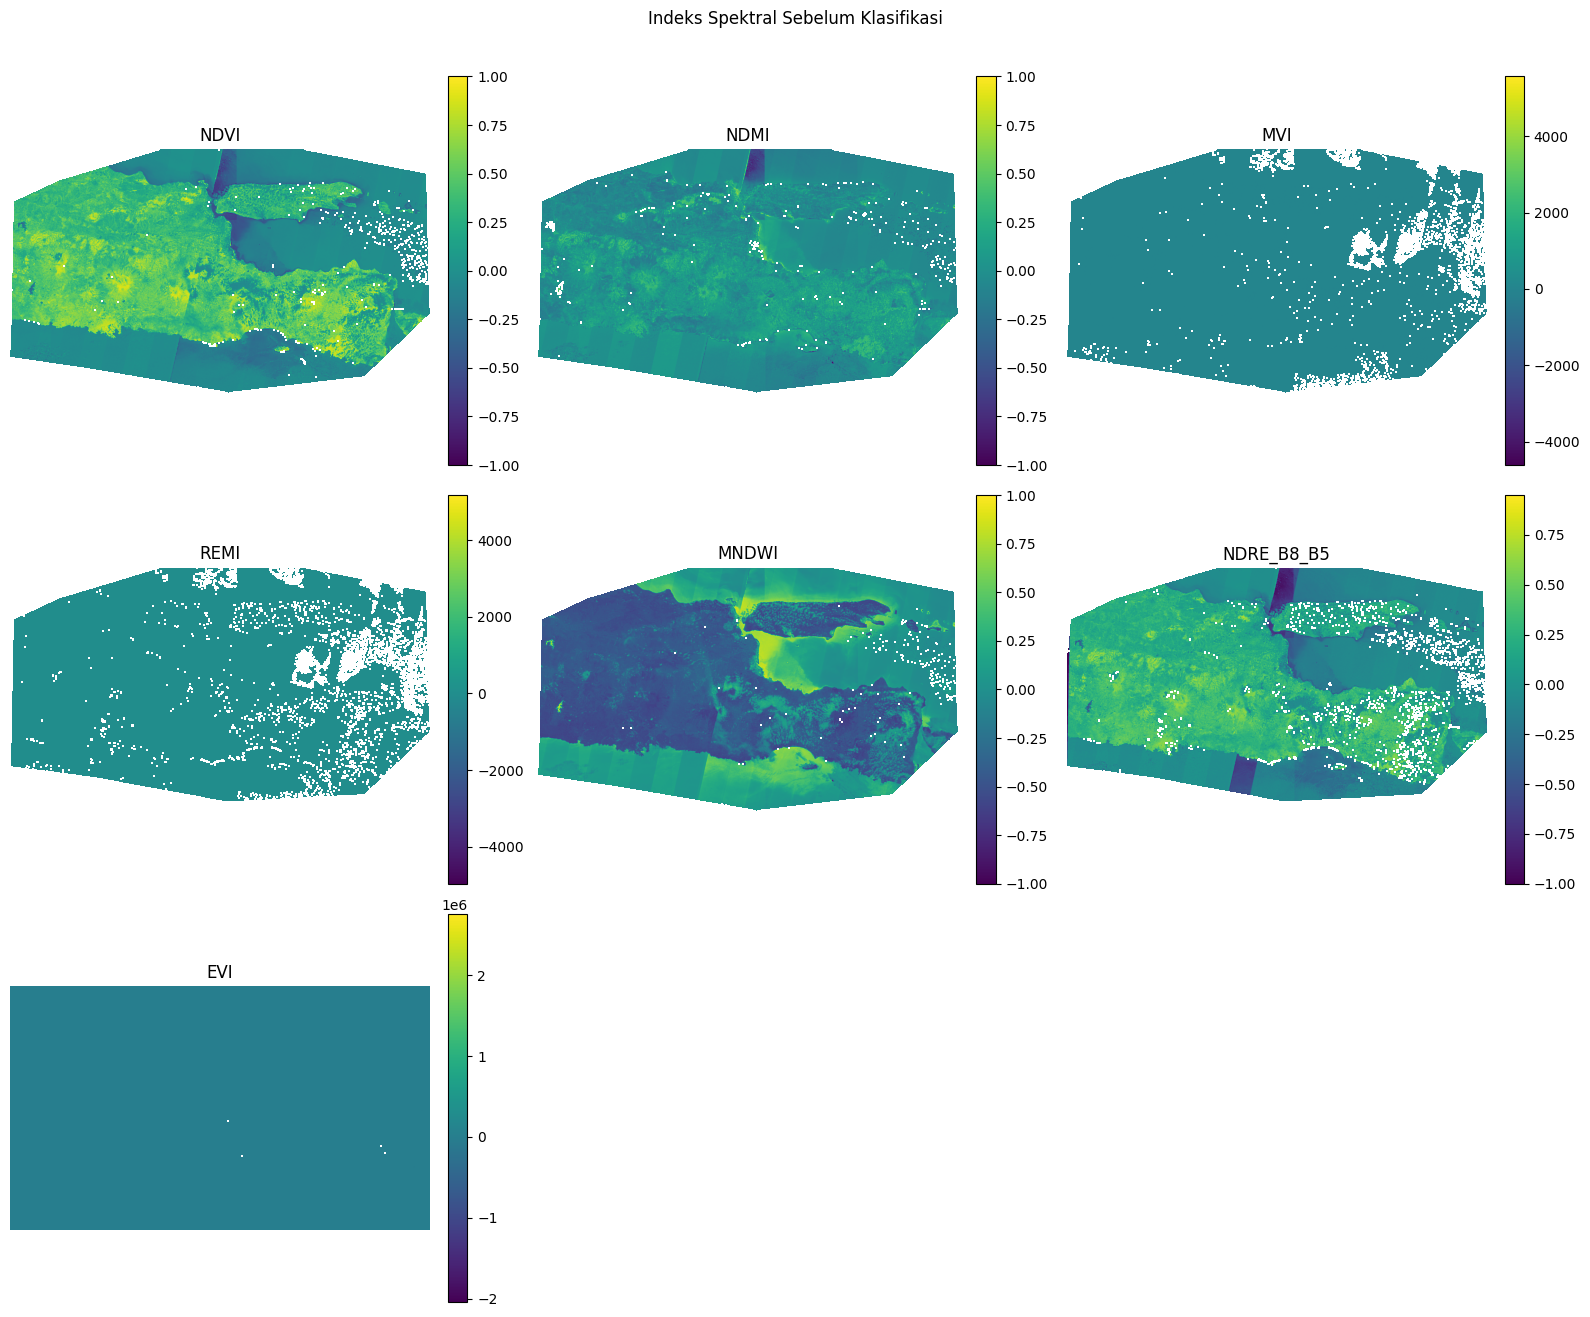

In [7]:
def safe_divide(numerator, denominator):
    """Pembagian aman: penyebut nol/nyaris nol atau nilai tidak valid menjadi NaN."""
    out = np.full_like(numerator, np.nan, dtype="float32")
    ok = (
        np.isfinite(numerator)
        & np.isfinite(denominator)
        & (np.abs(denominator) > 1e-8)
    )
    out[ok] = numerator[ok] / denominator[ok]
    return out
B2, B3, B4, B5 = bands["B2"], bands["B3"], bands["B4"], bands["B5"]
B8, B8A, B11 = bands["B8"], bands["B8A"], bands["B11"]
# Gabungkan band asli dan indeks sebagai fitur model.
features = {f"REF_{b}": bands[b] for b in bands}
# Hitung indeks spektral.
features["NDVI"] = safe_divide(B8 - B4, B8 + B4)
features["NDMI"] = safe_divide(B8 - B11, B8 + B11)
features["MVI"] = safe_divide(B8 - B3, B11 - B3)
features["MNDWI"] = safe_divide(B3 - B11, B3 + B11)
features["NDRE_B8_B5"] = safe_divide(B8 - B5, B8 + B5)
features["EVI"] = safe_divide(
    2.5 * (B8 - B4), B8 + 6 * B4 - 7.5 * B2 + 1
)
# REMI (Red-Edge Mangrove Index).
features["REMI"] = safe_divide(B5 - B4, B11 - B3)
# Gunakan urutan fitur yang sama untuk sampel dan prediksi.
feature_names = list(features.keys())
print("Jumlah fitur:", len(feature_names), feature_names)
# Visualisasikan indeks sebelum klasifikasi.
index_names = ["NDVI", "NDMI", "MVI", "REMI", "MNDWI", "NDRE_B8_B5", "EVI"]
fig, axes = plt.subplots(3, 3, figsize=(16, 13))
for ax, name in zip(axes.flat, index_names):
    im = ax.imshow(np.ma.masked_invalid(features[name]), cmap="viridis")
    ax.set_title(name)
    ax.axis("off")
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
for ax in axes.flat[len(index_names):]:
    ax.axis("off")
plt.suptitle("Indeks Spektral Sebelum Klasifikasi", y=1.01)
plt.tight_layout()
plt.show()

## Ekstraksi fitur sampel

Kode mengambil nilai band dan indeks pada titik representatif setiap poligon. Nilai tersebut menjadi fitur model, sedangkan atribut kelas menjadi target prediksi. Sampel dengan geometri, label, atau fitur tidak valid perlu diperiksa.


In [8]:
def extract_pixel_values(x, y, array, transform):
    row, col = rasterio.transform.rowcol(transform, x, y)
    if 0 <= row < array.shape[0] and 0 <= col < array.shape[1]:
        return array[row, col]
    return np.nan

points = samples.geometry.representative_point()
rows = []
for idx, point in zip(samples.index, points):
    record = {
        "class_name": samples.loc[idx, "class_name"],
        "sample_id": samples.loc[idx, "sample_id"] if "sample_id" in samples.columns else idx
    }
    for name, arr in features.items():
        record[name] = extract_pixel_values(point.x, point.y, arr, ref_transform)
    rows.append(record)

training_df = pd.DataFrame(rows).replace([np.inf, -np.inf], np.nan)
before = len(training_df)
training_df = training_df.dropna(subset=feature_names + ["class_name"]).copy()
print(f"Sampel sebelum pemeriksaan nilai raster: {before}")
print(f"Sampel valid setelah menghapus NoData/NaN: {len(training_df)}")
display(training_df["class_name"].value_counts().to_frame("jumlah"))
if training_df["class_name"].nunique() != 5:
    raise ValueError("Tidak semua lima kelas tersisa setelah ekstraksi. Periksa CRS, posisi sampel, dan NoData.")


Sampel sebelum pemeriksaan nilai raster: 350
Sampel valid setelah menghapus NoData/NaN: 348


,jumlah
class_name,
Hutan,70
Lahan pertanian,70
Bangunan,70
Mangrove,70
Perairan,68


## Pembagian data

Data dibagi menjadi 80% pelatihan dan 20% pengujian dengan stratifikasi agar proporsi kelas terjaga. Hasil pengujian ini merupakan estimasi awal; data validasi independen memberi penilaian generalisasi yang lebih kuat.


In [9]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay, f1_score

X = training_df[feature_names].astype("float32")
y = training_df["class_name"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
print("Training:", len(X_train), "Testing:", len(X_test))
display(y_train.value_counts().to_frame("training"))
display(y_test.value_counts().to_frame("testing"))

Training: 278 Testing: 70


,training
class_name,
Mangrove,56
Lahan pertanian,56
Bangunan,56
Hutan,56
Perairan,54


,testing
class_name,
Perairan,14
Lahan pertanian,14
Bangunan,14
Mangrove,14
Hutan,14


## Pelatihan dan perbandingan model

Random Forest, SVM, dan Decision Tree dilatih pada data pelatihan lalu dievaluasi pada data pengujian. Akurasi mengukur proporsi prediksi benar, sedangkan macro F1 memberi bobot yang sama pada F1 setiap kelas.


In [10]:
models = {
    "Random Forest": RandomForestClassifier(
        n_estimators=300, class_weight="balanced", random_state=42, n_jobs=-1
    ),
    "SVM": Pipeline([
        ("scaler", StandardScaler()),
        ("model", SVC(C=3, kernel="rbf", class_weight="balanced"))
    ]),
    "Decision Tree": DecisionTreeClassifier(
        class_weight="balanced", random_state=42, min_samples_leaf=2
    ),
}
results, fitted_models, predictions = [], {}, {}
for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    fitted_models[name] = model
    predictions[name] = pred
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Macro F1": f1_score(y_test, pred, average="macro"),
        "Weighted F1": f1_score(y_test, pred, average="weighted")
    })
results_df = pd.DataFrame(results).sort_values("Macro F1", ascending=False)
display(results_df)
best_model_name = results_df.iloc[0]["Model"]
best_model = fitted_models[best_model_name]
print("Model terbaik berdasarkan Macro F1:", best_model_name)

,Model,Accuracy,Macro F1,Weighted F1
0,Random Forest,0.742857,0.747143,0.747143
1,SVM,0.714286,0.718740,0.718740
2,Decision Tree,0.614286,0.621667,0.621667


Model terbaik berdasarkan Macro F1: Random Forest


## Evaluasi per kelas

Confusion matrix menunjukkan kelas sebenarnya dan hasil prediksi. Perhatikan kesalahan antara Mangrove dan Hutan, serta nilai precision, recall, dan F1 untuk setiap kelas.



 Random Forest
                 precision    recall  f1-score   support

          Hutan       0.58      0.79      0.67        14
       Perairan       0.79      0.79      0.79        14
Lahan pertanian       0.69      0.79      0.73        14
       Bangunan       0.91      0.71      0.80        14
       Mangrove       0.90      0.64      0.75        14

       accuracy                           0.74        70
      macro avg       0.77      0.74      0.75        70
   weighted avg       0.77      0.74      0.75        70



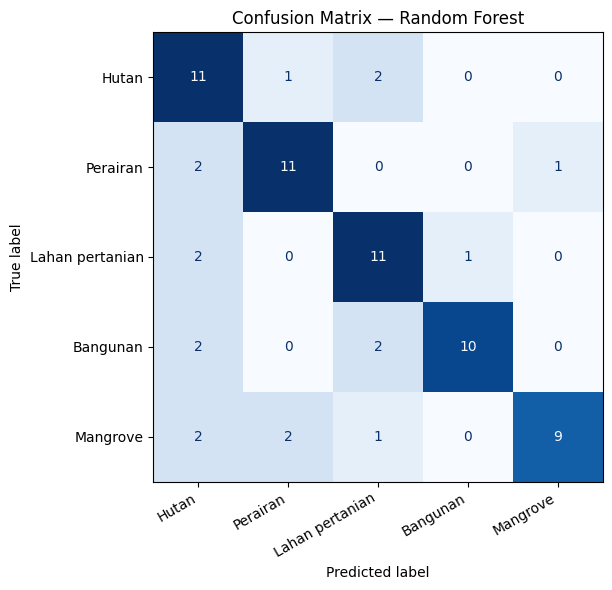


 SVM
                 precision    recall  f1-score   support

          Hutan       0.59      0.71      0.65        14
       Perairan       0.73      0.79      0.76        14
Lahan pertanian       0.60      0.64      0.62        14
       Bangunan       0.83      0.71      0.77        14
       Mangrove       0.91      0.71      0.80        14

       accuracy                           0.71        70
      macro avg       0.73      0.71      0.72        70
   weighted avg       0.73      0.71      0.72        70



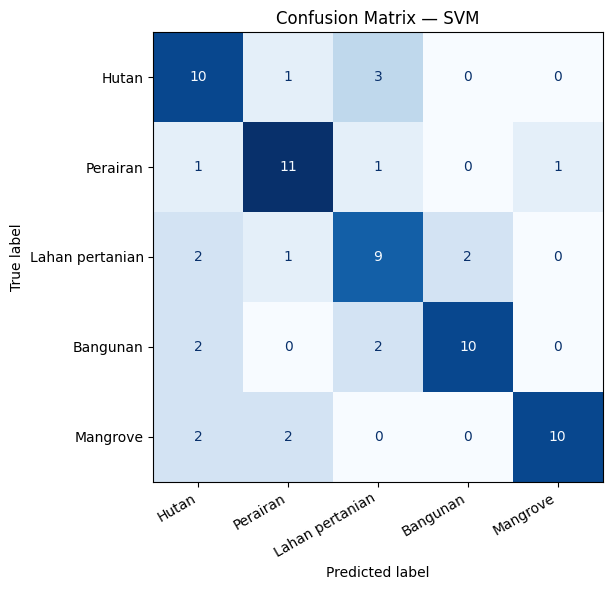


 Decision Tree
                 precision    recall  f1-score   support

          Hutan       0.50      0.57      0.53        14
       Perairan       0.56      0.71      0.62        14
Lahan pertanian       0.50      0.57      0.53        14
       Bangunan       0.90      0.64      0.75        14
       Mangrove       0.80      0.57      0.67        14

       accuracy                           0.61        70
      macro avg       0.65      0.61      0.62        70
   weighted avg       0.65      0.61      0.62        70



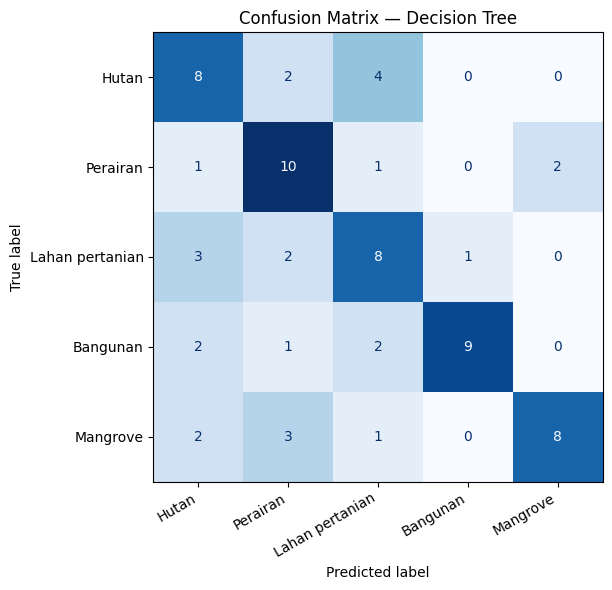

Kesalahan silang Hutan <-> Mangrove: 2


,aktual,prediksi
295,Mangrove,Hutan
282,Mangrove,Hutan


In [11]:
class_order = ["Hutan", "Perairan", "Lahan pertanian", "Bangunan", "Mangrove"]
for name, pred in predictions.items():
    print("\n", name)
    print(classification_report(y_test, pred, labels=class_order, zero_division=0))
    cm = confusion_matrix(y_test, pred, labels=class_order)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_order)
    fig, ax = plt.subplots(figsize=(7, 6))
    disp.plot(ax=ax, cmap="Blues", values_format="d", colorbar=False)
    ax.set_title(f"Confusion Matrix — {name}")
    plt.xticks(rotation=30, ha="right")
    plt.tight_layout()
    plt.show()

best_pred = predictions[best_model_name]
check = pd.DataFrame({"aktual": y_test, "prediksi": best_pred})
hm_errors = check[
    ((check["aktual"] == "Mangrove") & (check["prediksi"] == "Hutan")) |
    ((check["aktual"] == "Hutan") & (check["prediksi"] == "Mangrove"))
]
print("Kesalahan silang Hutan <-> Mangrove:", len(hm_errors))
display(hm_errors)

## Kepentingan fitur Random Forest

Feature importance menunjukkan fitur yang berkontribusi pada pemisahan kelas dalam model. Nilainya membantu membandingkan peran band dan indeks, tetapi bukan bukti sebab-akibat atau jaminan performa di wilayah lain.


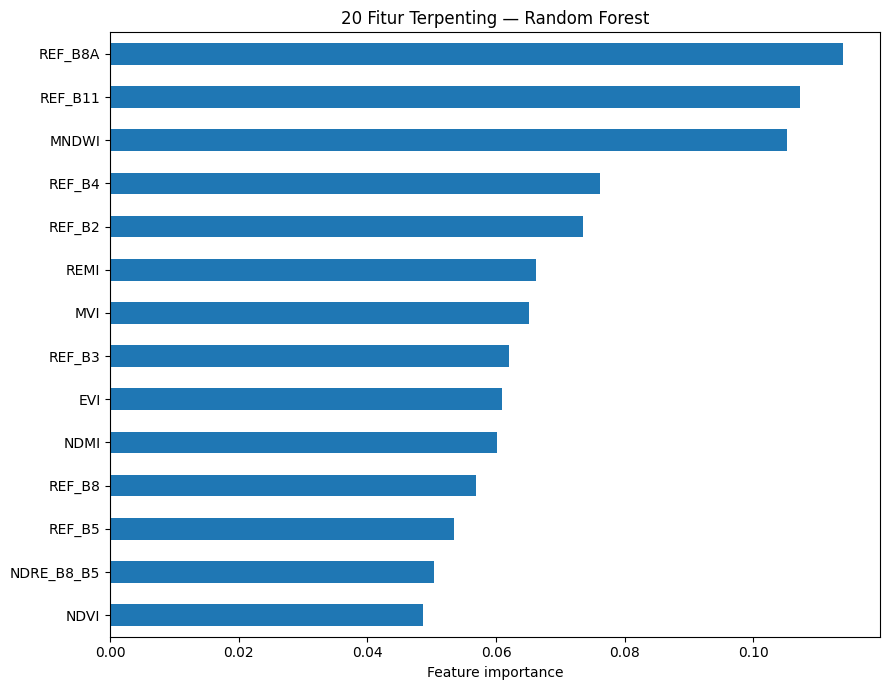

,importance
REF_B8A,0.113969
REF_B11,0.107249
MNDWI,0.105274
REF_B4,0.076098
REF_B2,0.073575
REMI,0.066238
MVI,0.065108
REF_B3,0.061975
EVI,0.060970
NDMI,0.060188


In [12]:
rf = fitted_models["Random Forest"]
importance = pd.Series(rf.feature_importances_, index=feature_names).sort_values()
plt.figure(figsize=(9, 7))
importance.tail(20).plot(kind="barh")
plt.title("20 Fitur Terpenting — Random Forest")
plt.xlabel("Feature importance")
plt.tight_layout()
plt.show()
display(importance.sort_values(ascending=False).to_frame("importance").head(20))

## Klasifikasi raster dan penyimpanan GeoTIFF

Model Random Forest diterapkan pada piksel dengan fitur valid. Pemrosesan per blok membantu mengendalikan penggunaan memori. Hasil disimpan sebagai GeoTIFF dengan informasi spasial dari raster referensi.


In [13]:
class_to_id = {"Hutan": 1, "Perairan": 2, "Lahan pertanian": 3, "Bangunan": 4, "Mangrove": 5}
id_to_class = {v: k for k, v in class_to_id.items()}
feature_stack = np.stack([features[n] for n in feature_names], axis=-1)
prediction_map = np.zeros((height, width), dtype=np.uint8)

block_rows = 128
for row_start in range(0, height, block_rows):
    row_end = min(row_start + block_rows, height)
    block = feature_stack[row_start:row_end, :, :]
    mask = np.all(np.isfinite(block), axis=-1)
    if mask.any():
        pred = best_model.predict(block[mask].reshape(-1, len(feature_names)))
        prediction_map[row_start:row_end, :][mask] = np.array([class_to_id[p] for p in pred], dtype=np.uint8)
    print(f"Baris diproses: {row_end}/{height}")

tif_out = OUTPUT_DIR / "klasifikasi_tutupan_lahan_5_kelas.tif"
profile = ref_profile.copy()
profile.update(dtype="uint8", count=1, nodata=0, compress="lzw")
with rasterio.open(tif_out, "w", **profile) as dst:
    dst.write(prediction_map, 1)
print("GeoTIFF tersimpan:", tif_out)

Baris diproses: 128/1452
Baris diproses: 256/1452
Baris diproses: 384/1452
Baris diproses: 512/1452
Baris diproses: 640/1452
Baris diproses: 768/1452
Baris diproses: 896/1452
Baris diproses: 1024/1452
Baris diproses: 1152/1452
Baris diproses: 1280/1452
Baris diproses: 1408/1452
Baris diproses: 1452/1452
GeoTIFF tersimpan: c:\Users\LENOVO\PSD\pertemuan_6\data\hasil_klasifikasi\klasifikasi_tutupan_lahan_5_kelas.tif


## Visualisasi hasil klasifikasi

Peta menampilkan sebaran lima kelas hasil prediksi. Periksa pola kelas yang tidak wajar dan bandingkan hasilnya dengan citra sumber atau data referensi.


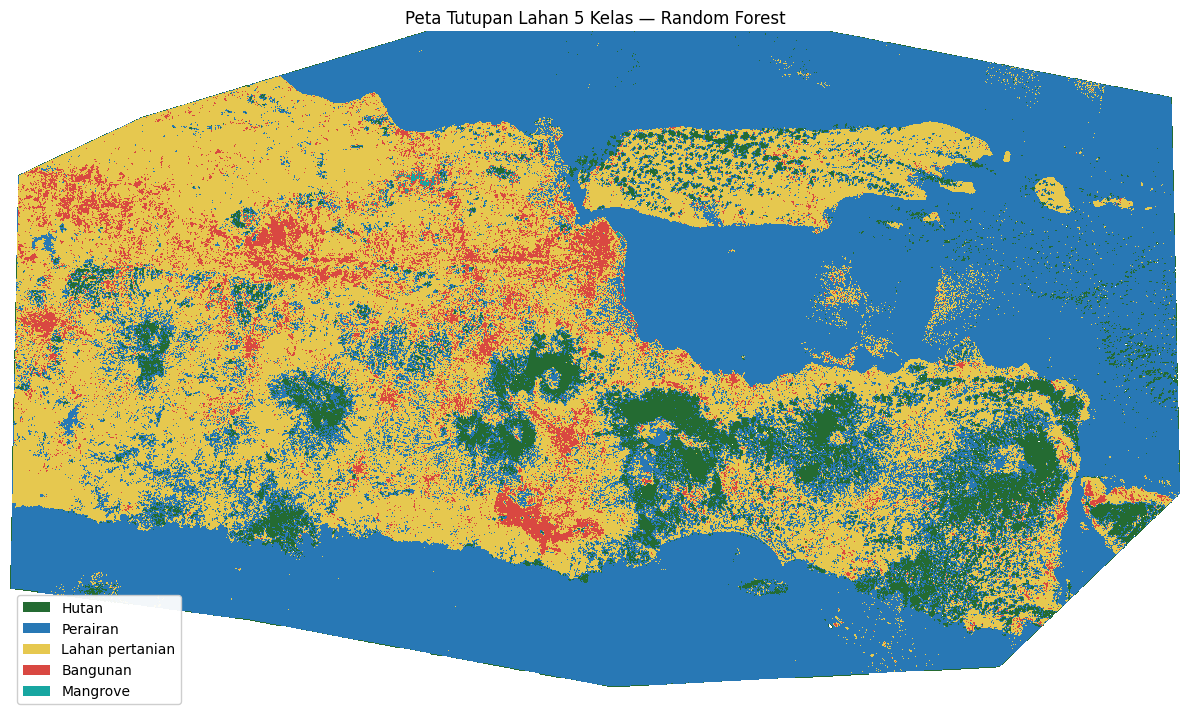

In [14]:
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch
colors = ["#ffffff", "#246b32", "#2878b5", "#e6c84f", "#d94841", "#17a6a1"]
cmap = ListedColormap(colors)
norm = BoundaryNorm([-0.5, 0.5, 1.5, 2.5, 3.5, 4.5, 5.5], cmap.N)
fig, ax = plt.subplots(figsize=(12, 8))
ax.imshow(prediction_map, cmap=cmap, norm=norm)
ax.set_title(f"Peta Tutupan Lahan 5 Kelas — {best_model_name}")
ax.axis("off")
legend_items = [
    Patch(facecolor="#246b32", label="Hutan"),
    Patch(facecolor="#2878b5", label="Perairan"),
    Patch(facecolor="#e6c84f", label="Lahan pertanian"),
    Patch(facecolor="#d94841", label="Bangunan"),
    Patch(facecolor="#17a6a1", label="Mangrove"),
]
ax.legend(handles=legend_items, loc="lower left", framealpha=0.95)
plt.tight_layout()
plt.show()

## Ekspor hasil

Sel ini menyimpan raster klasifikasi, metrik evaluasi, dan tabel fitur. Jika ekspor vektor diaktifkan, hasil raster juga dikonversi ke GeoJSON; ukuran berkas dapat menjadi besar.


In [15]:
EXPORT_GEOJSON = True
if EXPORT_GEOJSON:
    records = []
    for geom, value in shapes(prediction_map, mask=(prediction_map > 0), transform=ref_transform, connectivity=4):
        class_id = int(value)
        records.append({"geometry": shape(geom), "class_id": class_id, "class_name": id_to_class[class_id]})
    result_gdf = gpd.GeoDataFrame(records, geometry="geometry", crs=ref_crs)
    geojson_out = OUTPUT_DIR / "klasifikasi_tutupan_lahan_5_kelas.geojson"
    result_gdf.to_file(geojson_out, driver="GeoJSON")
    print("GeoJSON tersimpan:", geojson_out, "| jumlah poligon:", len(result_gdf))

results_csv = OUTPUT_DIR / "evaluasi_model.csv"
training_csv = OUTPUT_DIR / "sampel_fitur_terekstrak.csv"
results_df.to_csv(results_csv, index=False)
training_df.to_csv(training_csv, index=False)
print("File output:")
for p in OUTPUT_DIR.iterdir():
    if p.is_file():
        print(p.name, f"({p.stat().st_size/1024/1024:.2f} MB)")

GeoJSON tersimpan: c:\Users\LENOVO\PSD\pertemuan_6\data\hasil_klasifikasi\klasifikasi_tutupan_lahan_5_kelas.geojson | jumlah poligon: 265849
File output:
evaluasi_model.csv (0.00 MB)
klasifikasi_tutupan_lahan_5_kelas.geojson (139.18 MB)
klasifikasi_tutupan_lahan_5_kelas.tif (0.58 MB)
peta_klasifikasi_jatim_lengkap.html (1.58 MB)
peta_mangrove_vs_bukan_mangrove.html (0.22 MB)
sampel_fitur_terekstrak.csv (0.05 MB)


## Peta interaktif Folium

Peta menampilkan setiap kelas sebagai layer yang dapat diaktifkan atau dinonaktifkan. Poligon sampel ditampilkan sebagai referensi, dan penggeser mengatur transparansi overlay.


Membangun peta interaktif dari hasil klasifikasi raster...
Peta interaktif disimpan: c:\Users\LENOVO\PSD\pertemuan_6\data\hasil_klasifikasi\peta_klasifikasi_jatim_lengkap.html



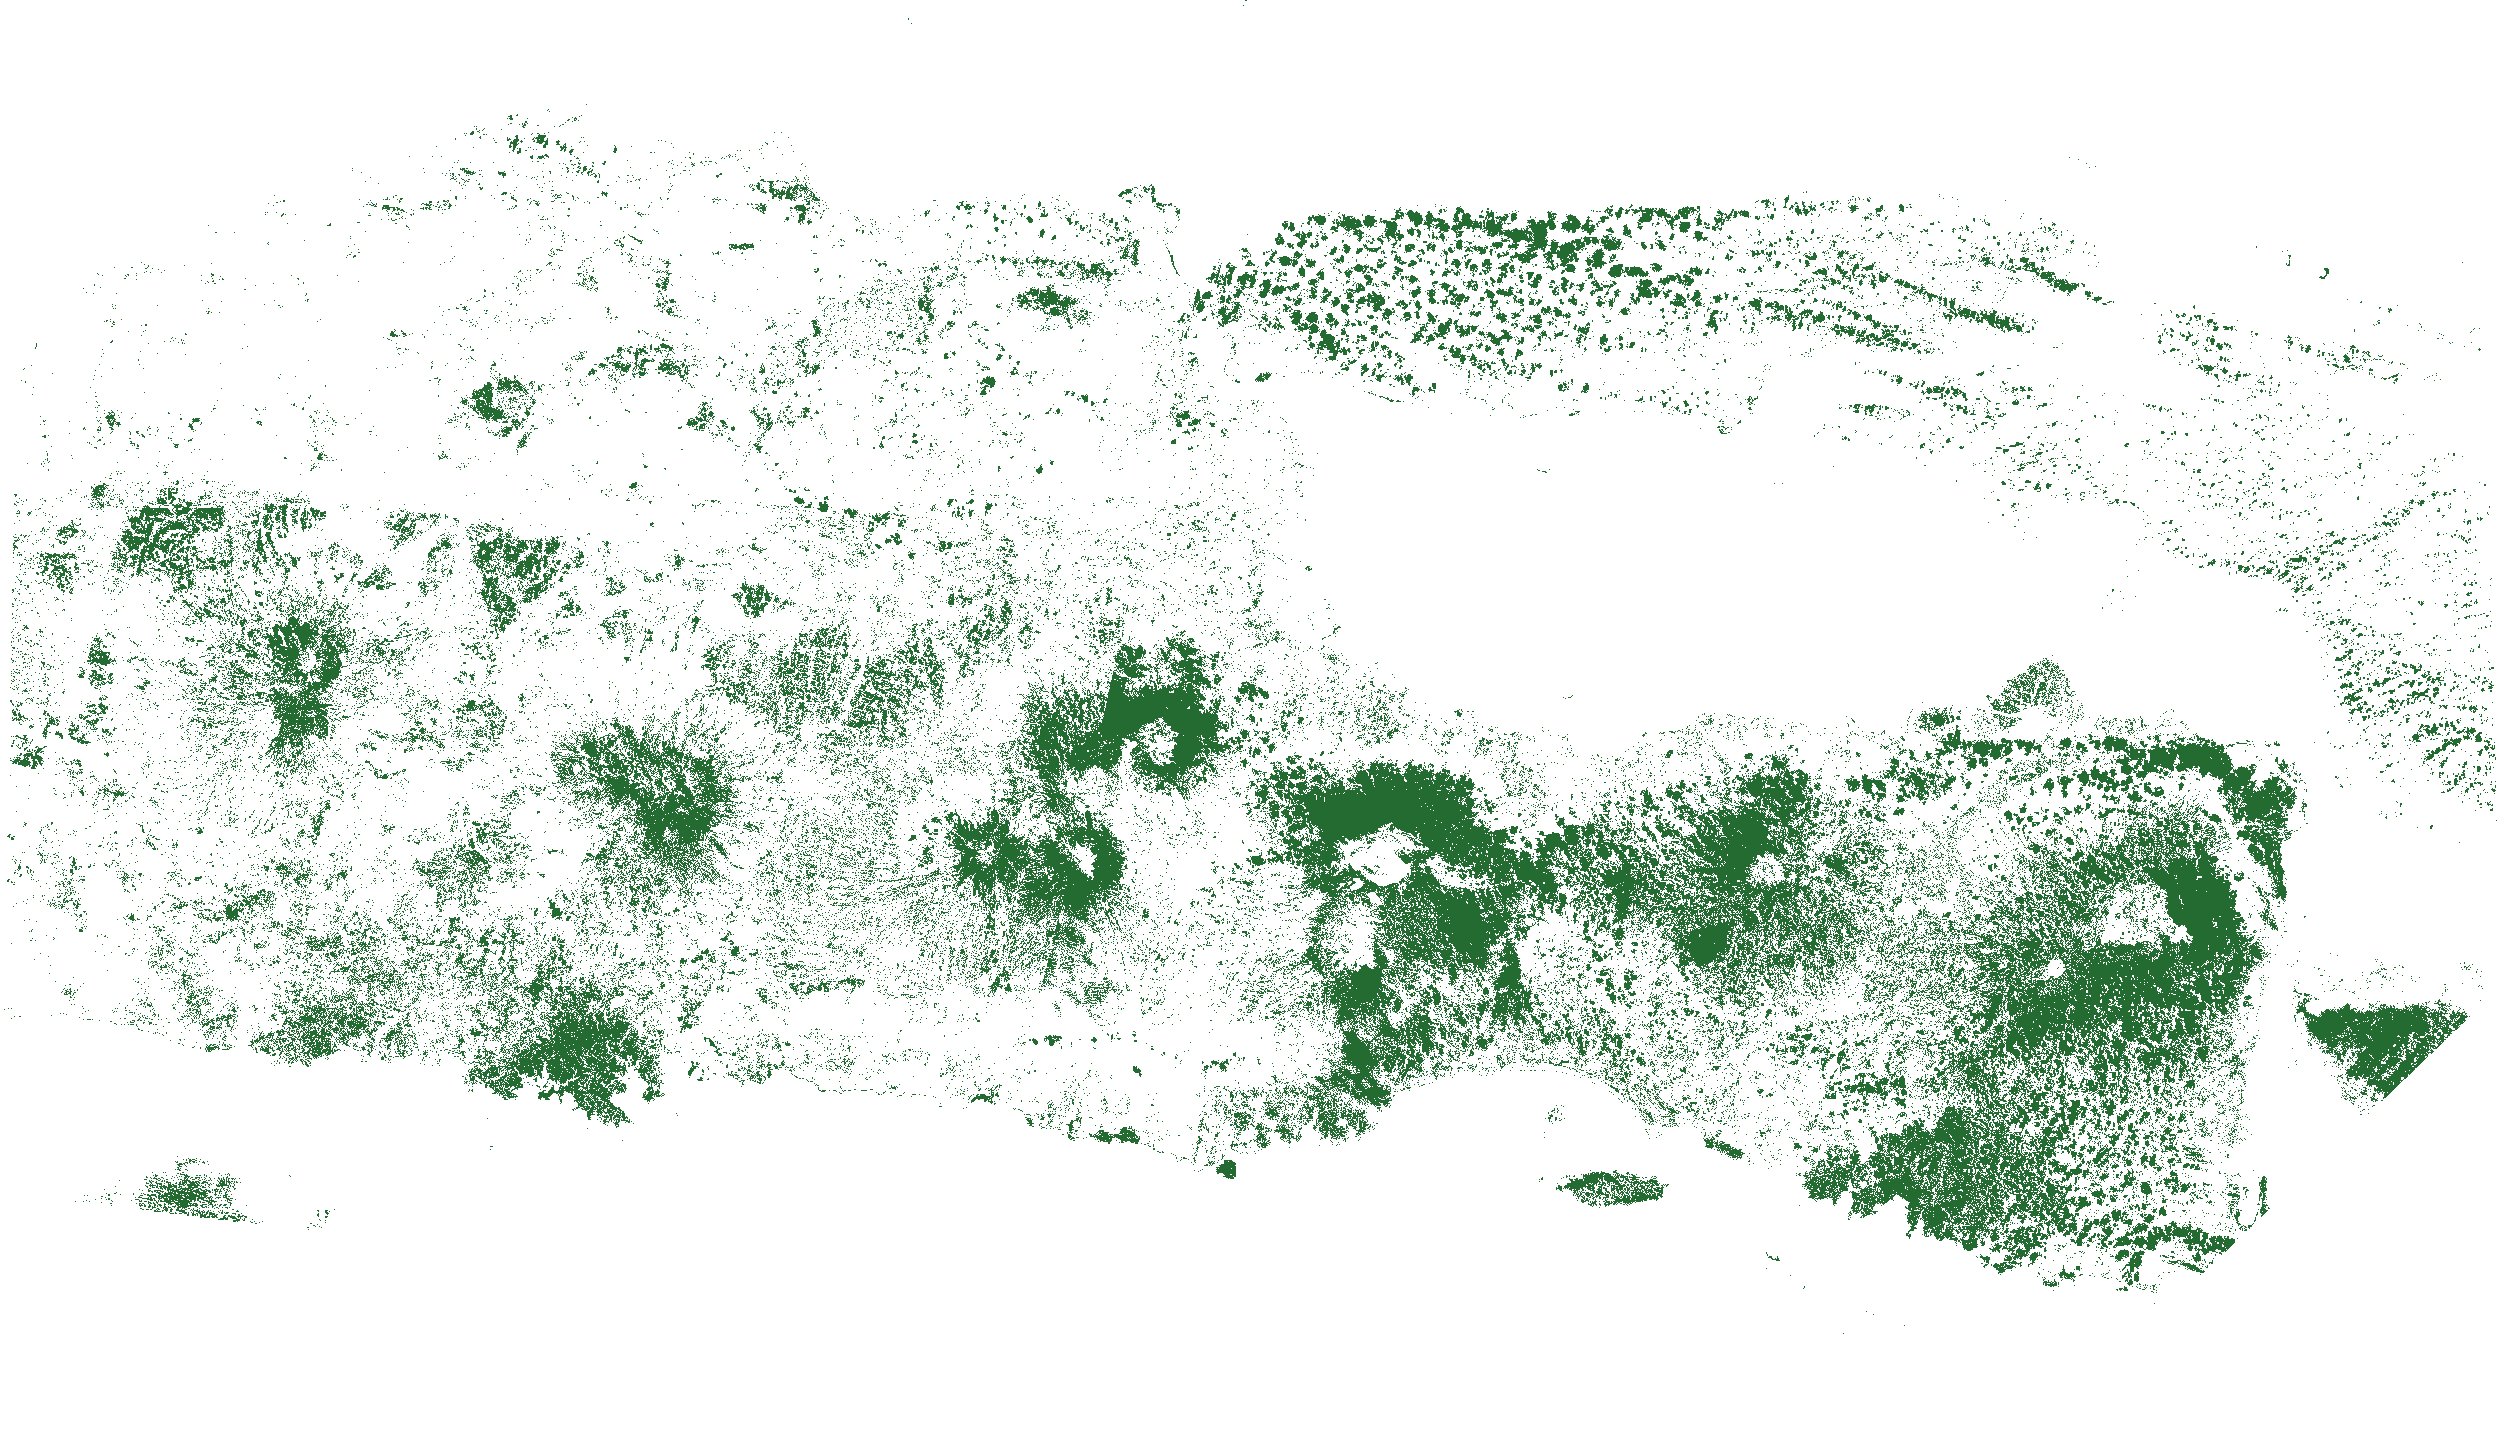
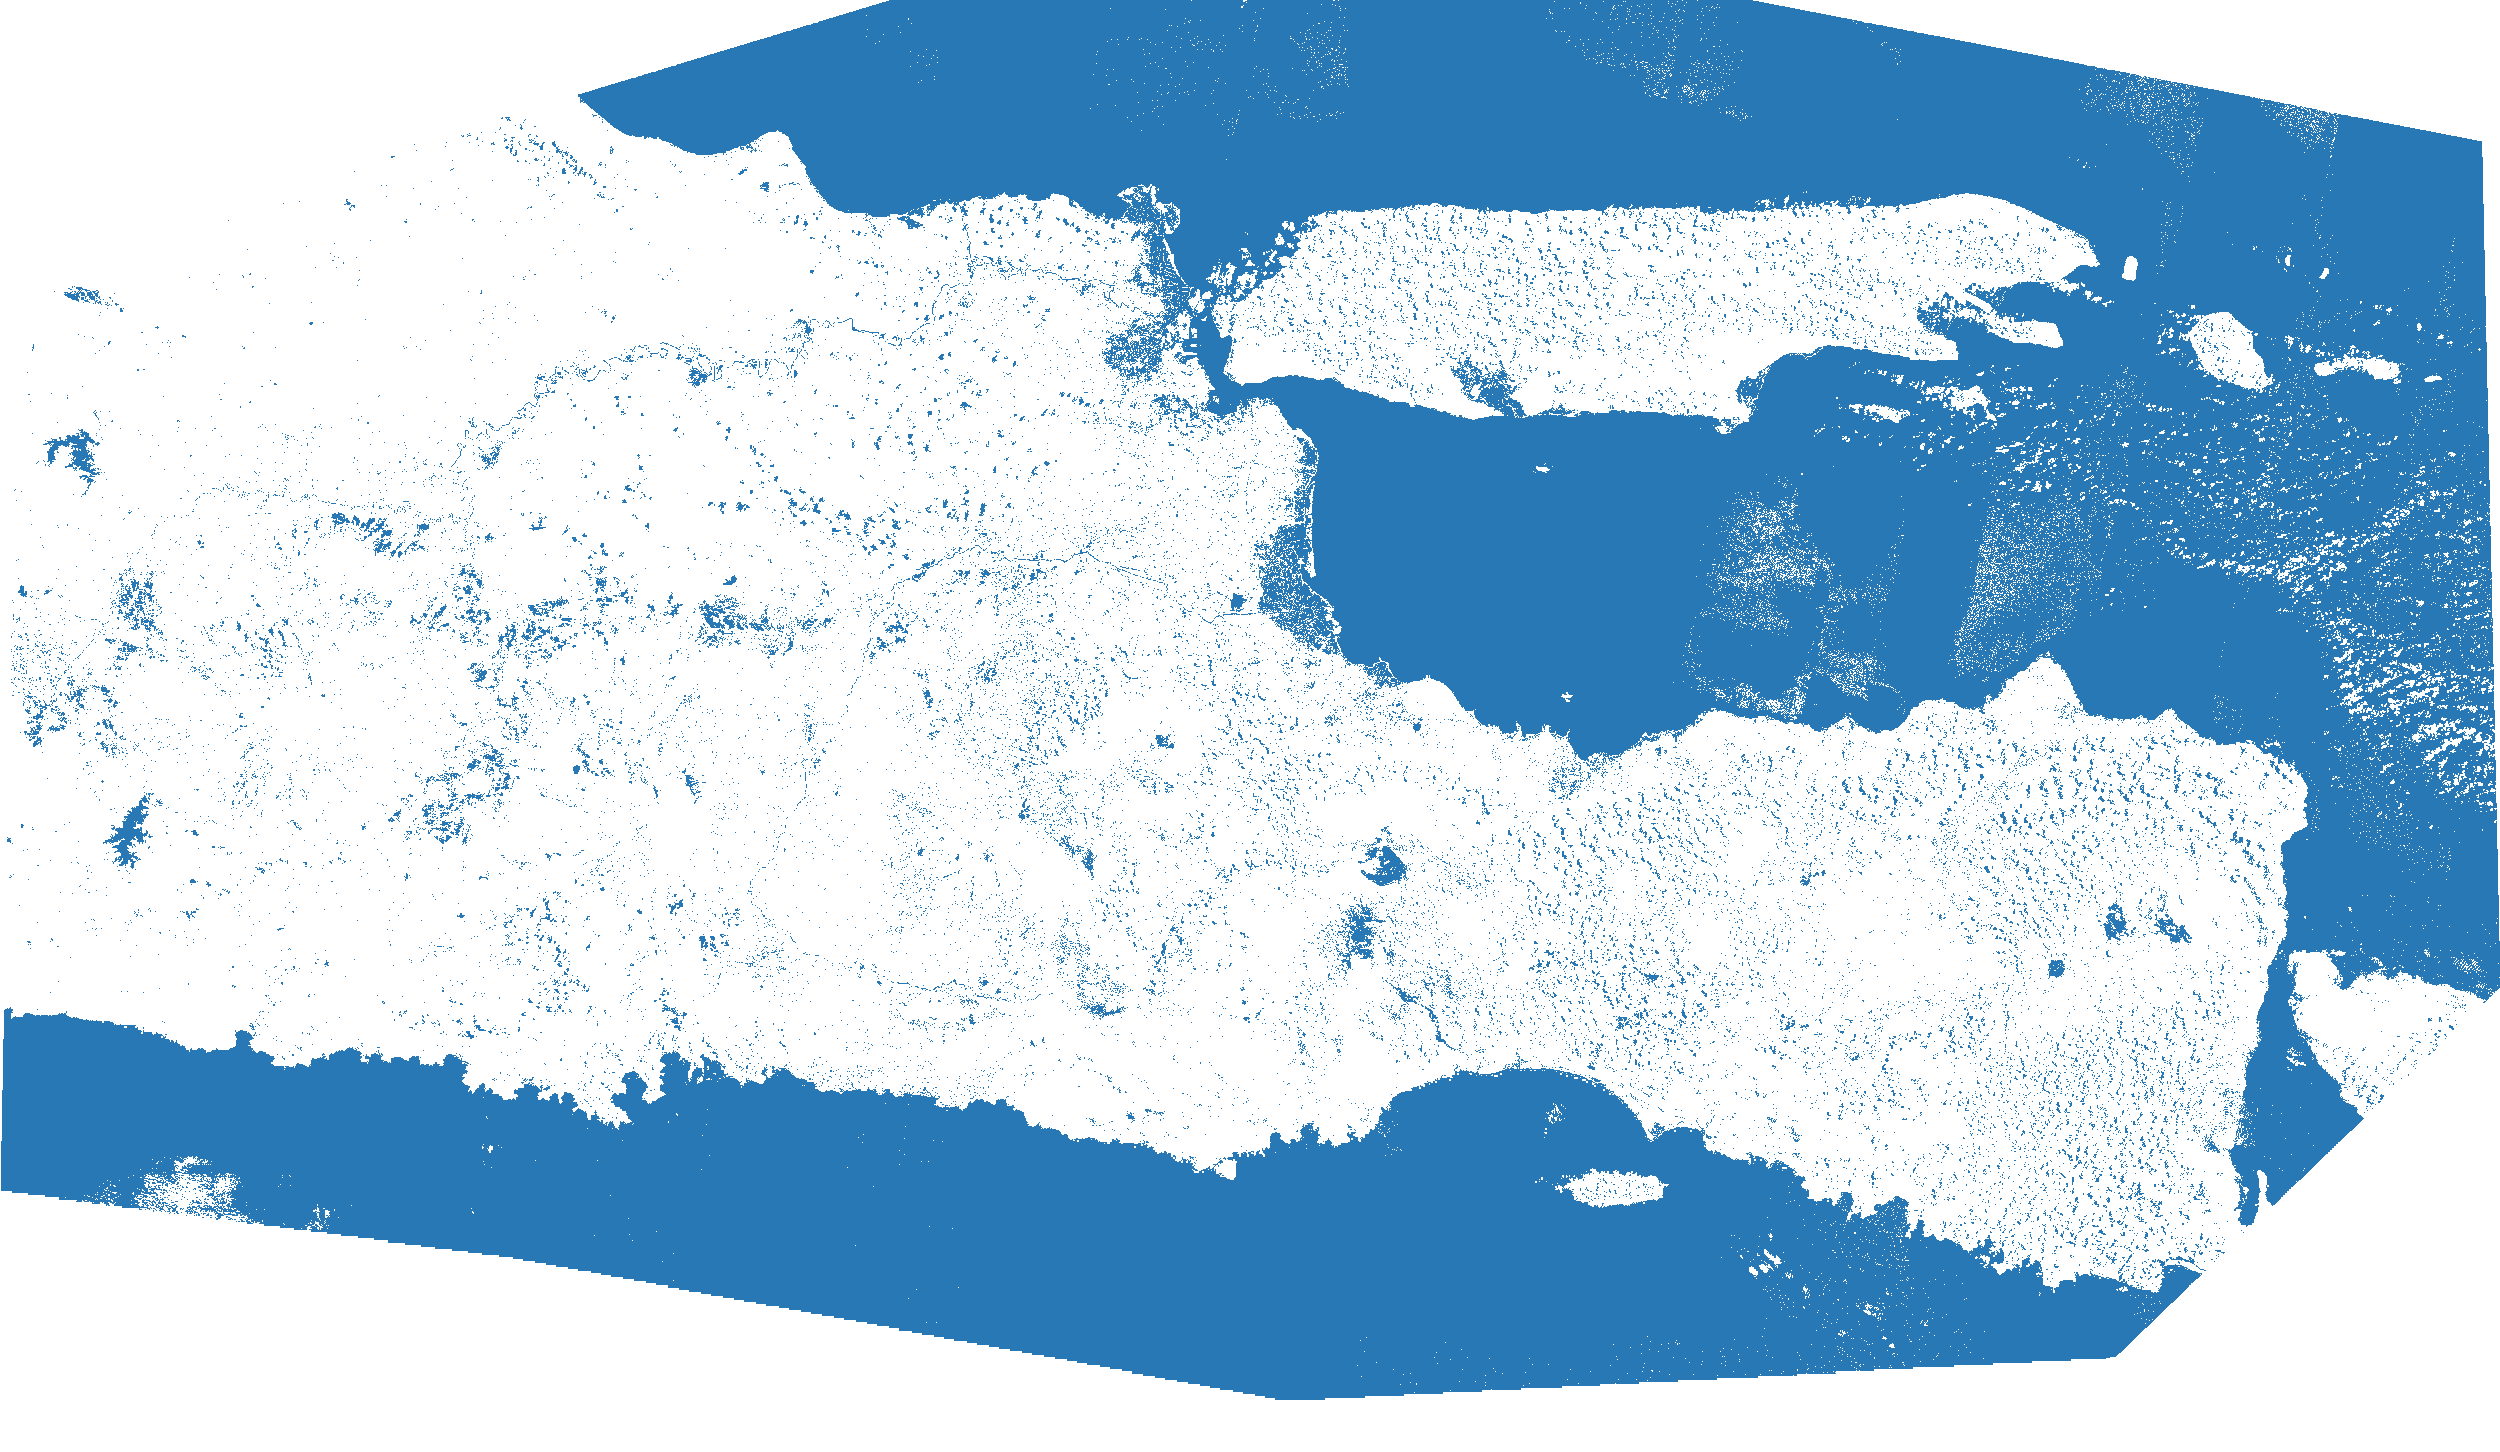
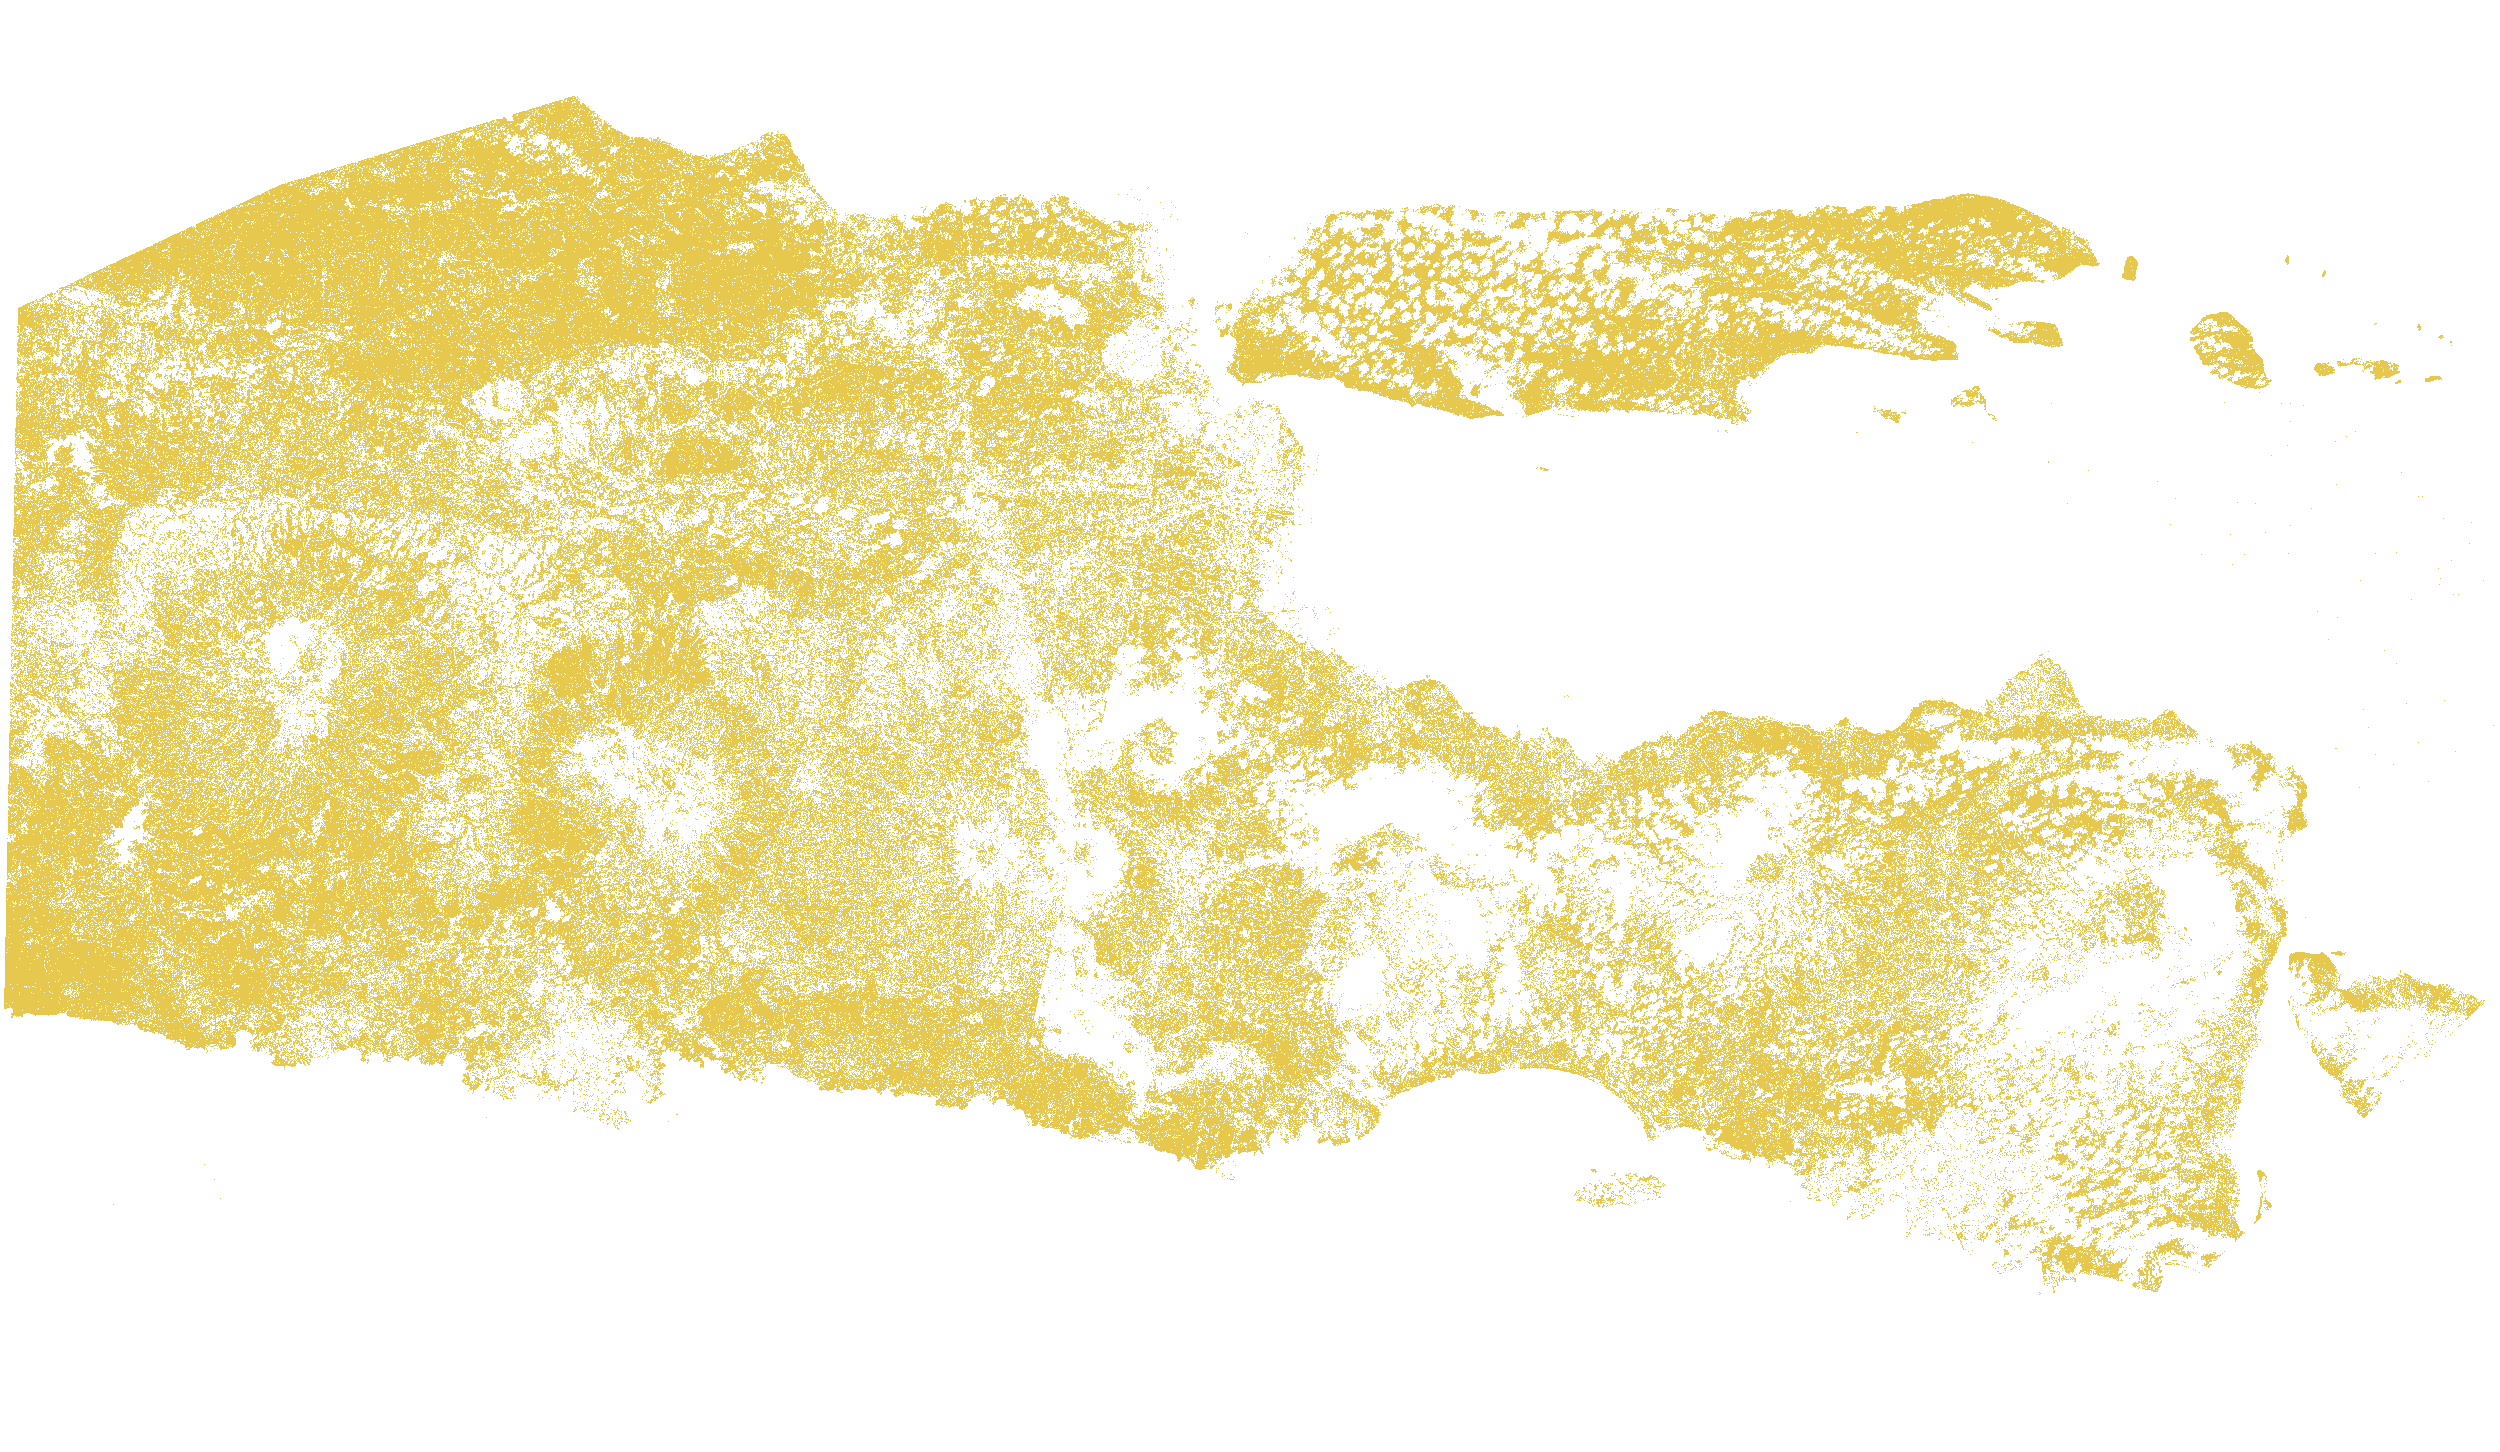
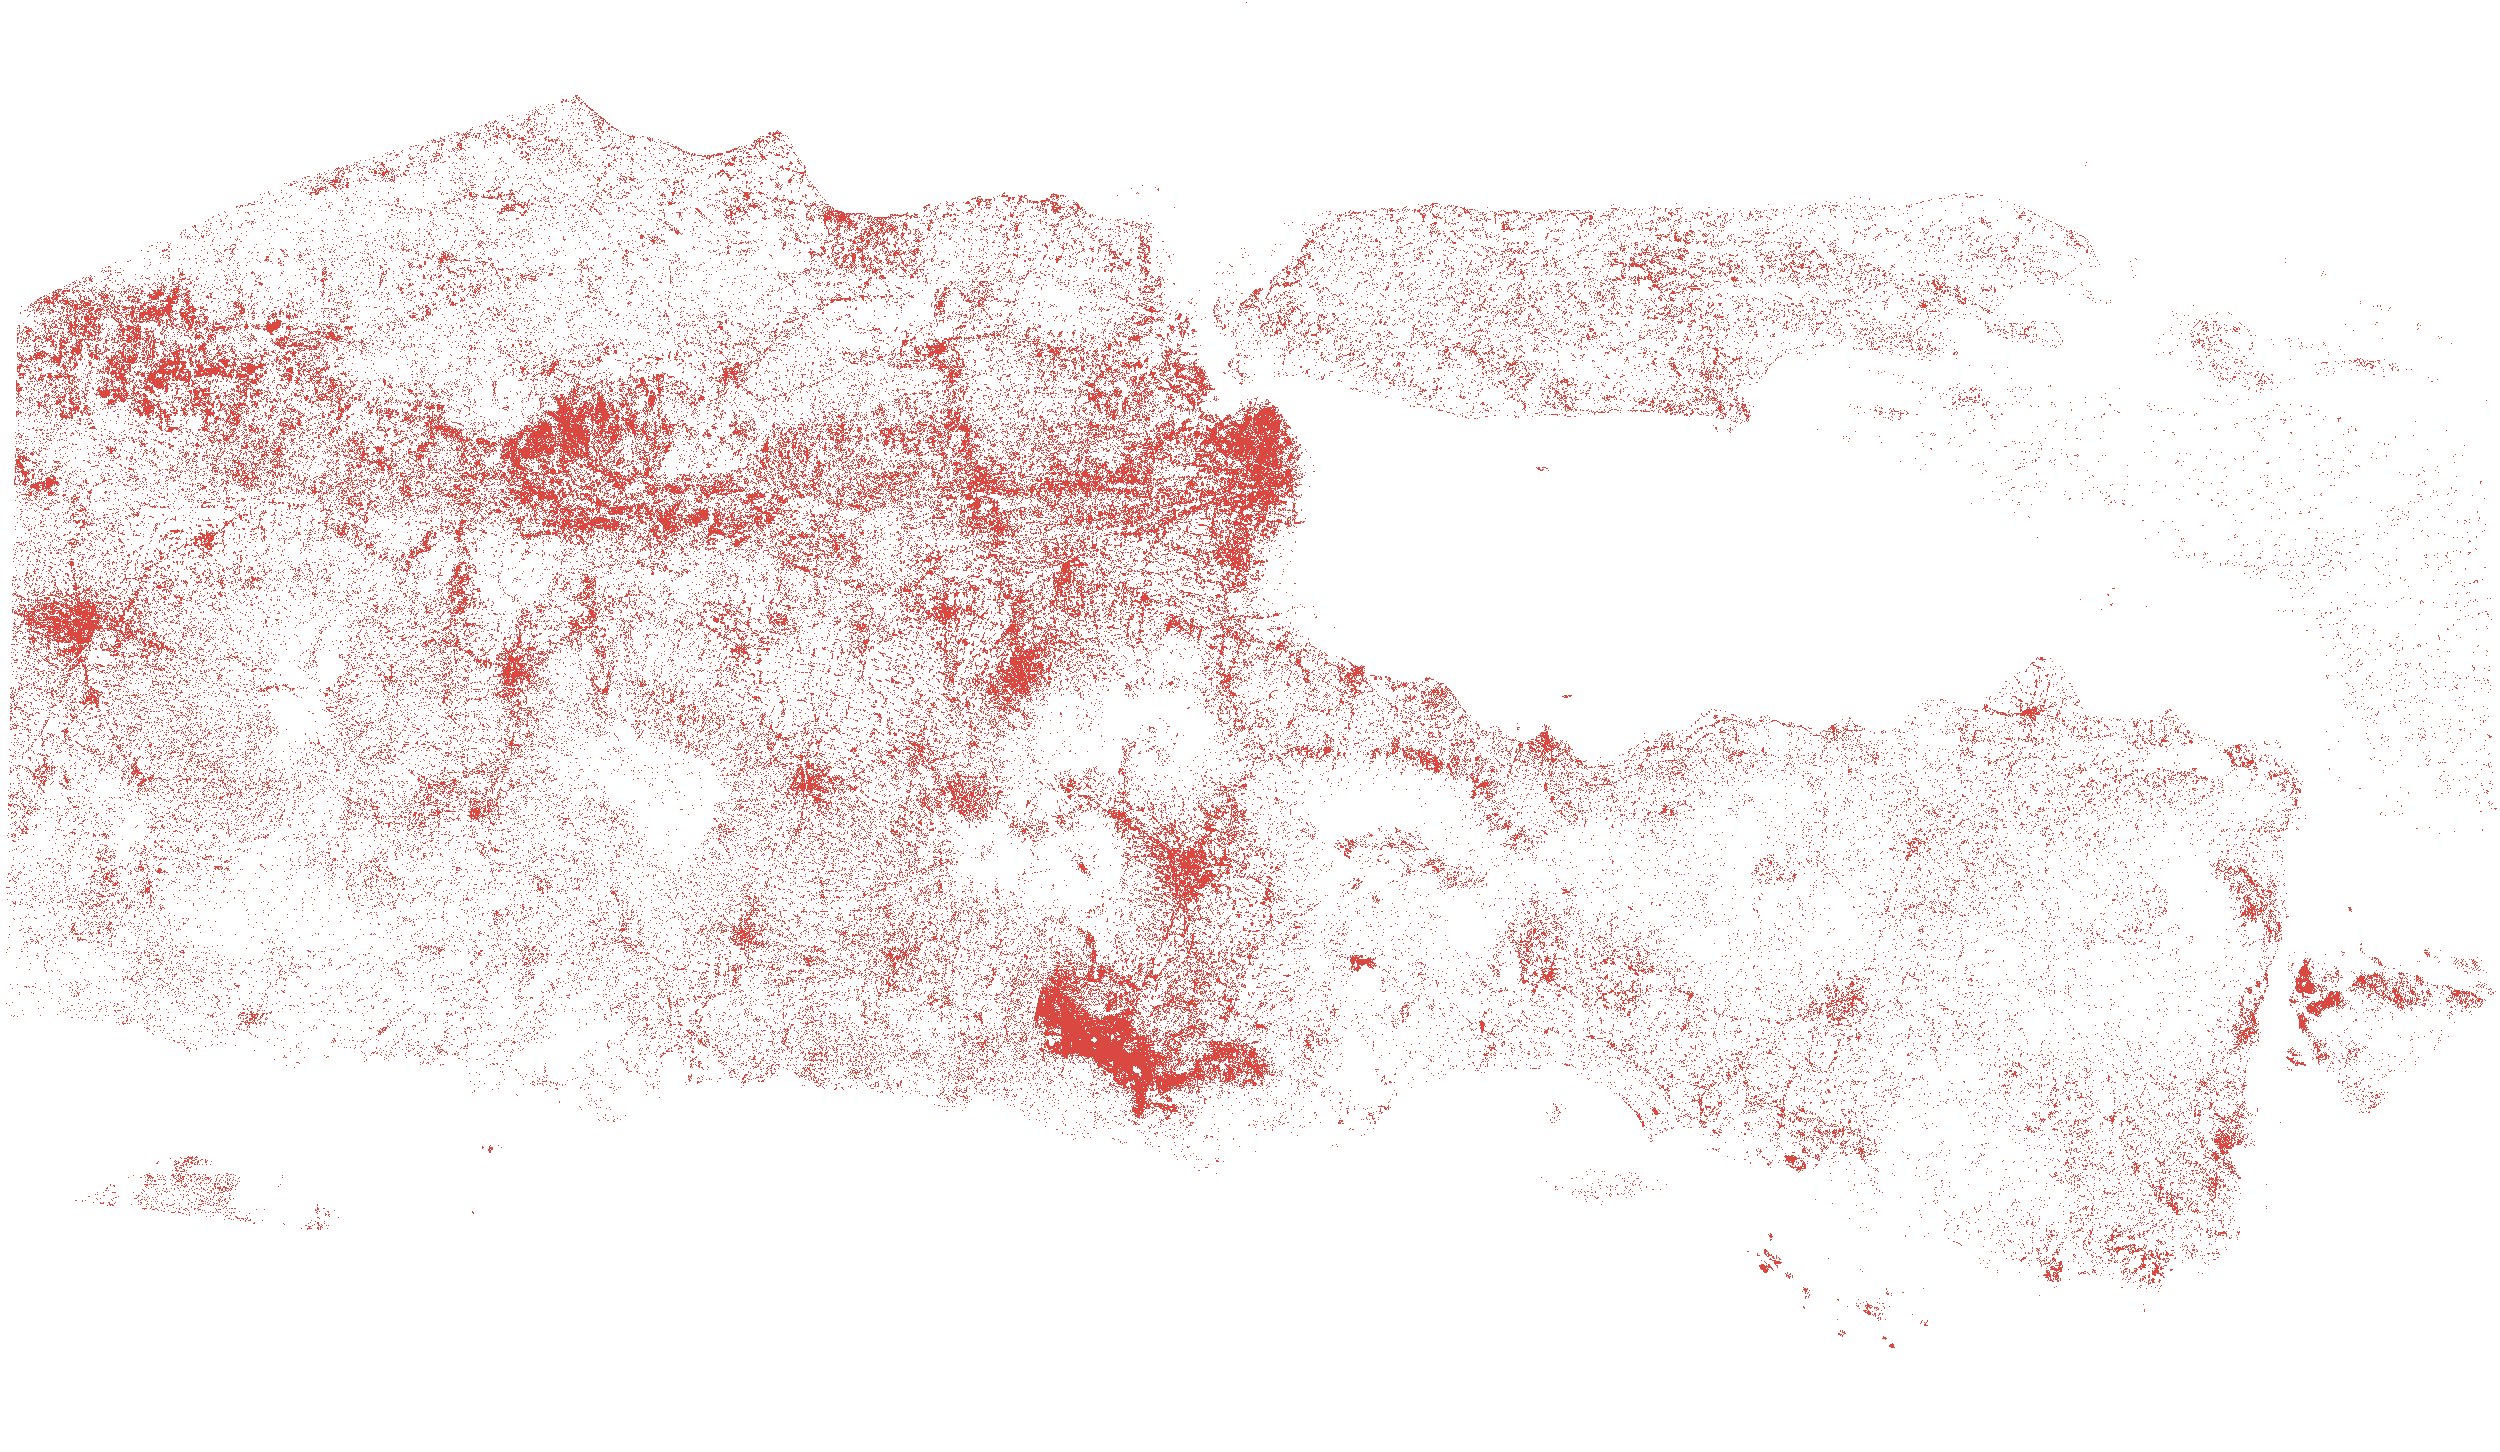
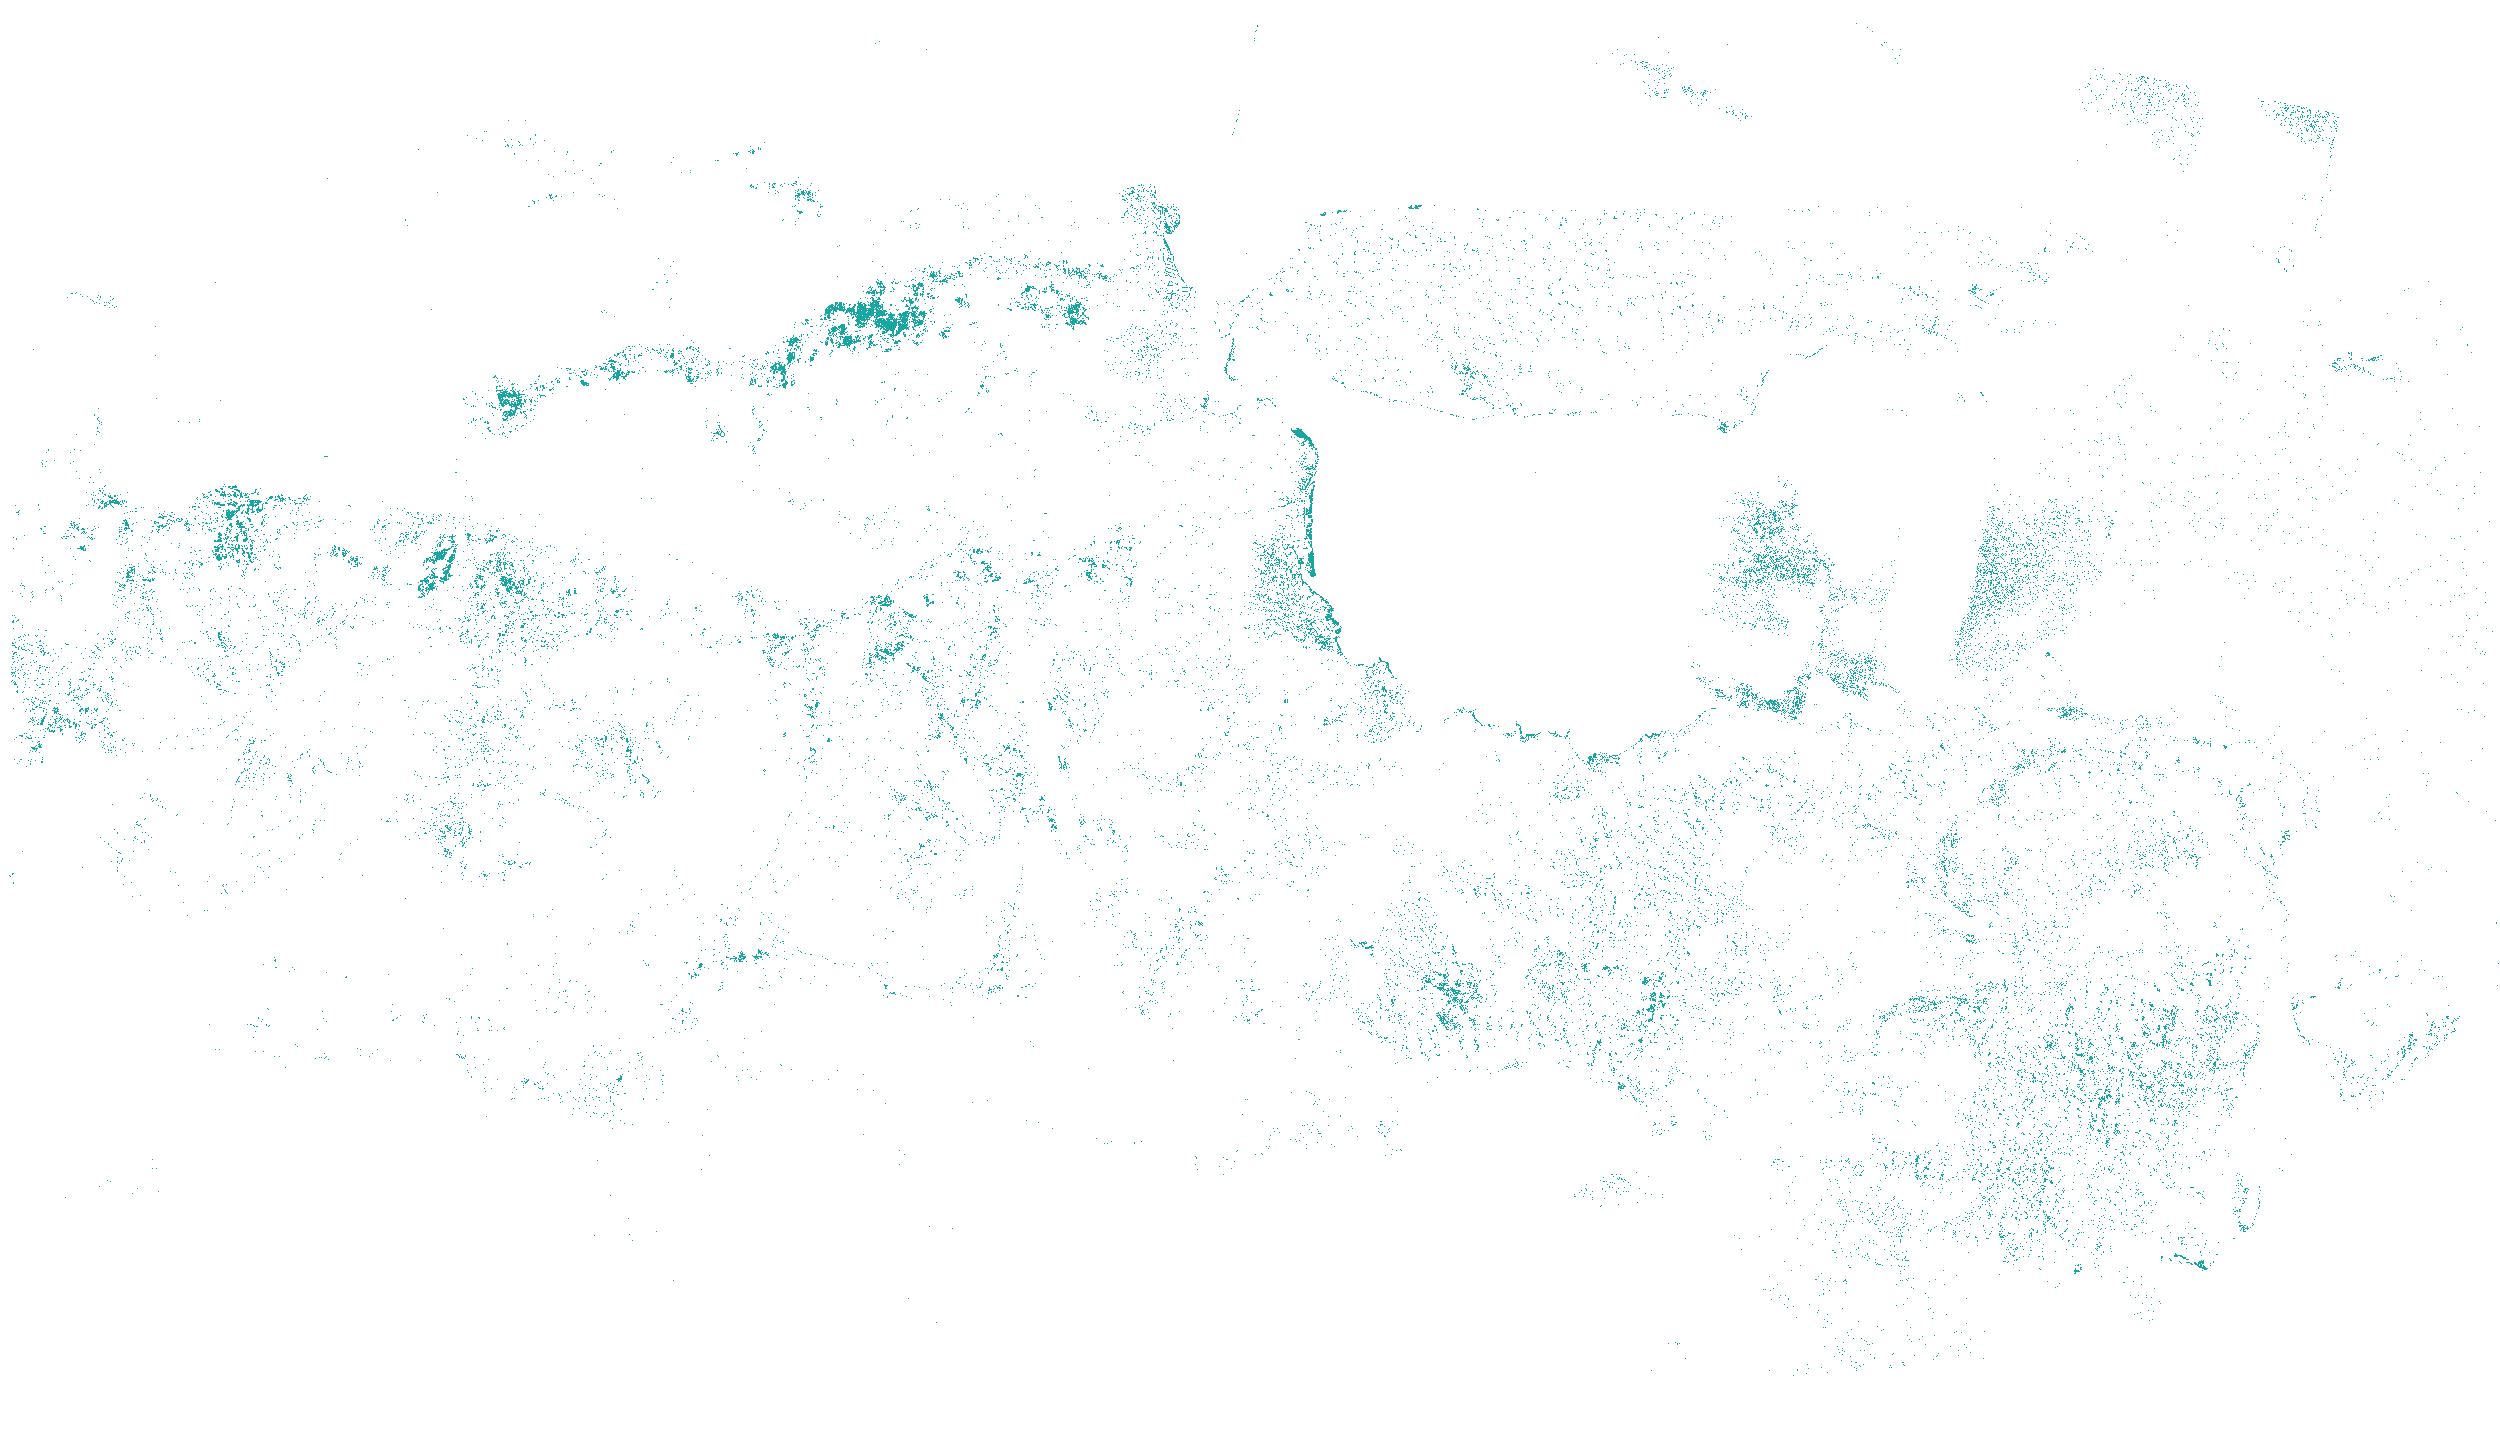

In [16]:
# Tetapkan warna untuk setiap kelas.
COLORS = {
    "Hutan": "#246b32",
    "Perairan": "#2878b5",
    "Lahan pertanian": "#e6c84f",
    "Bangunan": "#d94841",
    "Mangrove": "#17a6a1",
}
print("Membangun peta interaktif dari hasil klasifikasi raster...")
# Konversi batas raster ke koordinat geografis.
bounds_latlon = transform_bounds(ref_crs, "EPSG:4326", *bounds)
bounds_peta = [
    [bounds_latlon[1], bounds_latlon[0]],
    [bounds_latlon[3], bounds_latlon[2]],
]
pusat_peta = [
    (bounds_peta[0][0] + bounds_peta[1][0]) / 2,
    (bounds_peta[0][1] + bounds_peta[1][1]) / 2,
]
m = folium.Map(location=pusat_peta, zoom_start=8, tiles="OpenStreetMap")
# Buat overlay terpisah untuk setiap kelas.
for cls_name, color_hex in COLORS.items():
    class_id = class_to_id[cls_name]
    cls_mask = prediction_map == class_id
    if not np.any(cls_mask):
        print(f"Kelas {cls_name} tidak ditemukan; layer dilewati.")
        continue
    img_rgba = np.zeros((height, width, 4), dtype=np.uint8)
    r, g, b = mcolors.to_rgb(color_hex)
    img_rgba[cls_mask, 0] = int(r * 255)
    img_rgba[cls_mask, 1] = int(g * 255)
    img_rgba[cls_mask, 2] = int(b * 255)
    img_rgba[cls_mask, 3] = 255
    fg = folium.FeatureGroup(name=cls_name, overlay=True, control=True)
    raster_layers.ImageOverlay(
        image=img_rgba,
        bounds=bounds_peta,
        opacity=0.7,
        interactive=False,
        cross_origin=False,
    ).add_to(fg)
    fg.add_to(m)
# Tambahkan poligon sampel sebagai referensi.
if SAMPLE_FILE is not None and Path(SAMPLE_FILE).exists():
    sample_gdf = gpd.read_file(SAMPLE_FILE)
    if sample_gdf.crs is not None:
        sample_gdf = sample_gdf.to_crs("EPSG:4326")
    tooltip_fields = [c for c in ["class_name", "class_id"] if c in sample_gdf.columns]
    folium.GeoJson(
        sample_gdf,
        name="Poligon sampel",
        style_function=lambda feature: {
            "fillColor": "#ff0000",
            "fillOpacity": 0,
            "color": "red",
            "weight": 2,
        },
        tooltip=folium.GeoJsonTooltip(fields=tooltip_fields) if tooltip_fields else None,
    ).add_to(m)
# Atur transparansi overlay.
slider_html = """
<div style="position: fixed; top: 120px; left: 20px; z-index: 9999; background: white;
            padding: 10px; border-radius: 8px; box-shadow: 2px 2px 6px rgba(0,0,0,0.3); font-family: Arial;">
    <h4 style="margin: 0 0 5px 0; font-size: 14px;">Hasil klasifikasi</h4>
    <span style="font-size: 12px;">Transparansi</span><br>
    <input type="range" min="0" max="1" step="0.1" value="0.7"
           oninput="aturTransparansi(this.value)" style="width: 100%; margin-top: 5px;">
</div>
<script>
function aturTransparansi(nilaiOpacity) {
    document.querySelectorAll('.leaflet-image-layer').forEach(function(gambar) {
        gambar.style.opacity = nilaiOpacity;
    });
}
</script>
"""
m.get_root().html.add_child(Element(slider_html))
folium.LayerControl(collapsed=False).add_to(m)
nama_file_html = OUTPUT_DIR / "peta_klasifikasi_jatim_lengkap.html"
m.save(str(nama_file_html))
print("Peta interaktif disimpan:", nama_file_html)
display(m)

Membangun peta perbandingan Mangrove dan Bukan Mangrove...
Peta berhasil disimpan: c:\Users\LENOVO\PSD\pertemuan_6\data\hasil_klasifikasi\peta_mangrove_vs_bukan_mangrove.html
Piksel Mangrove: 48996
Piksel Bukan Mangrove: 3581004



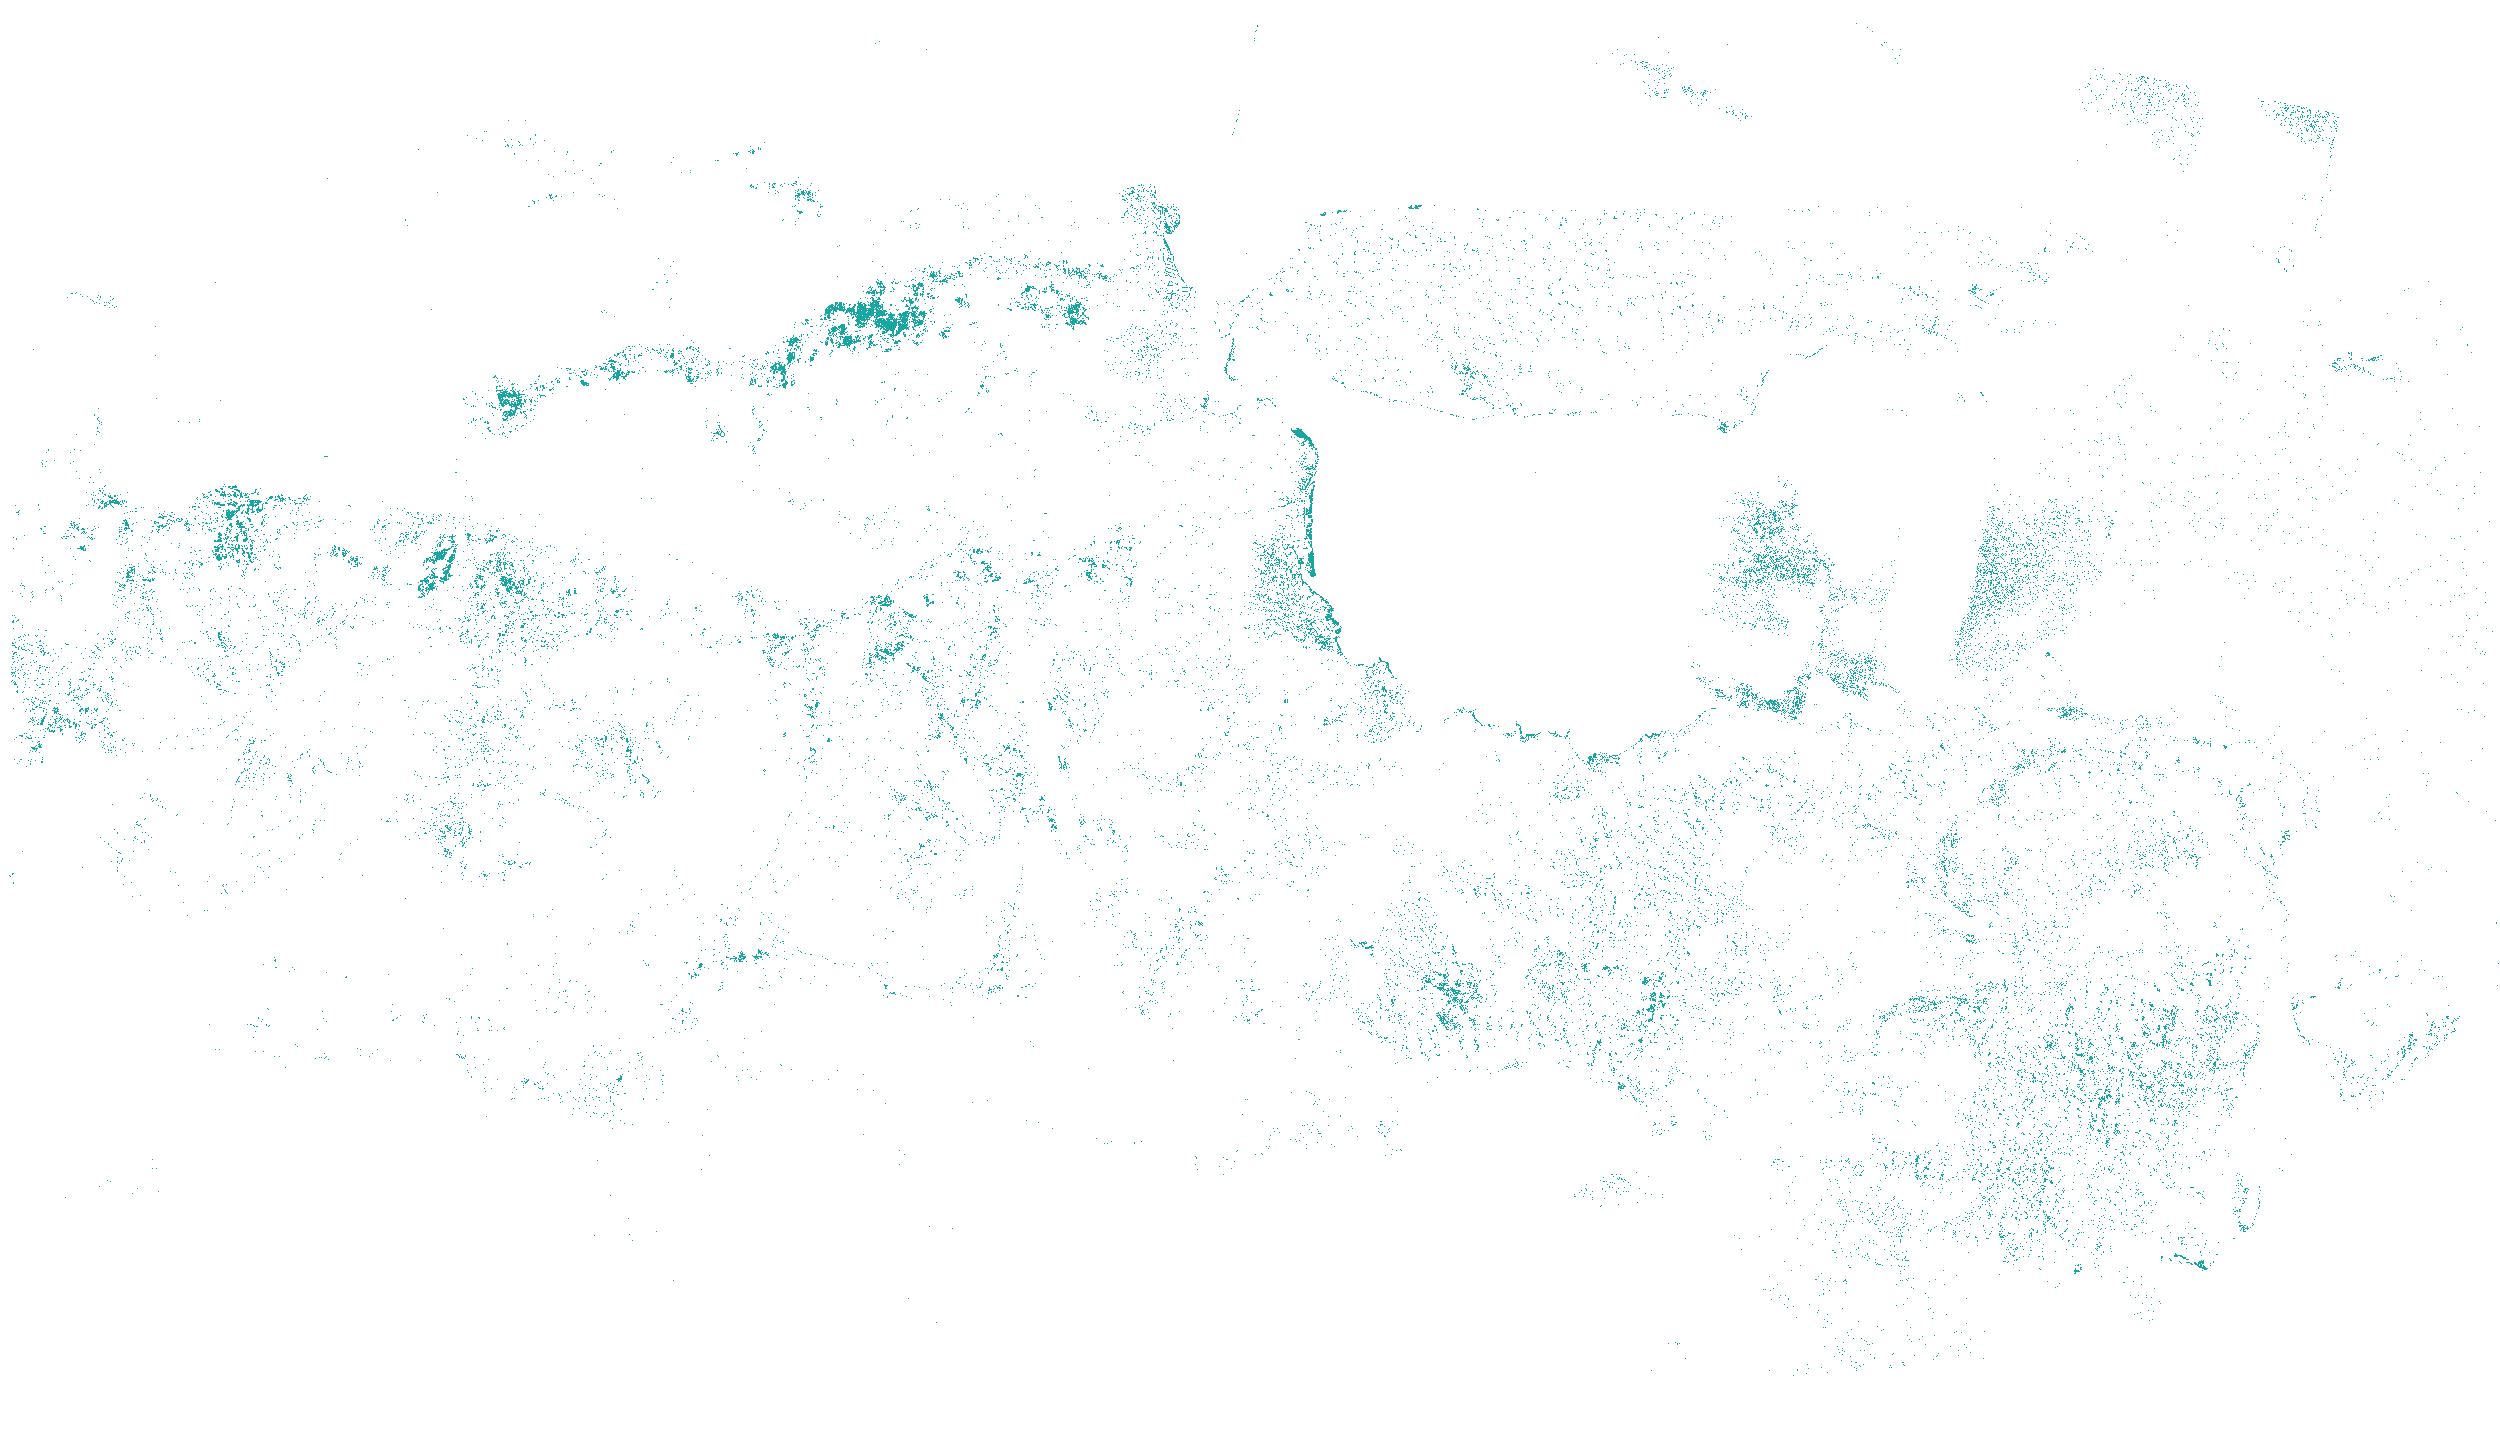
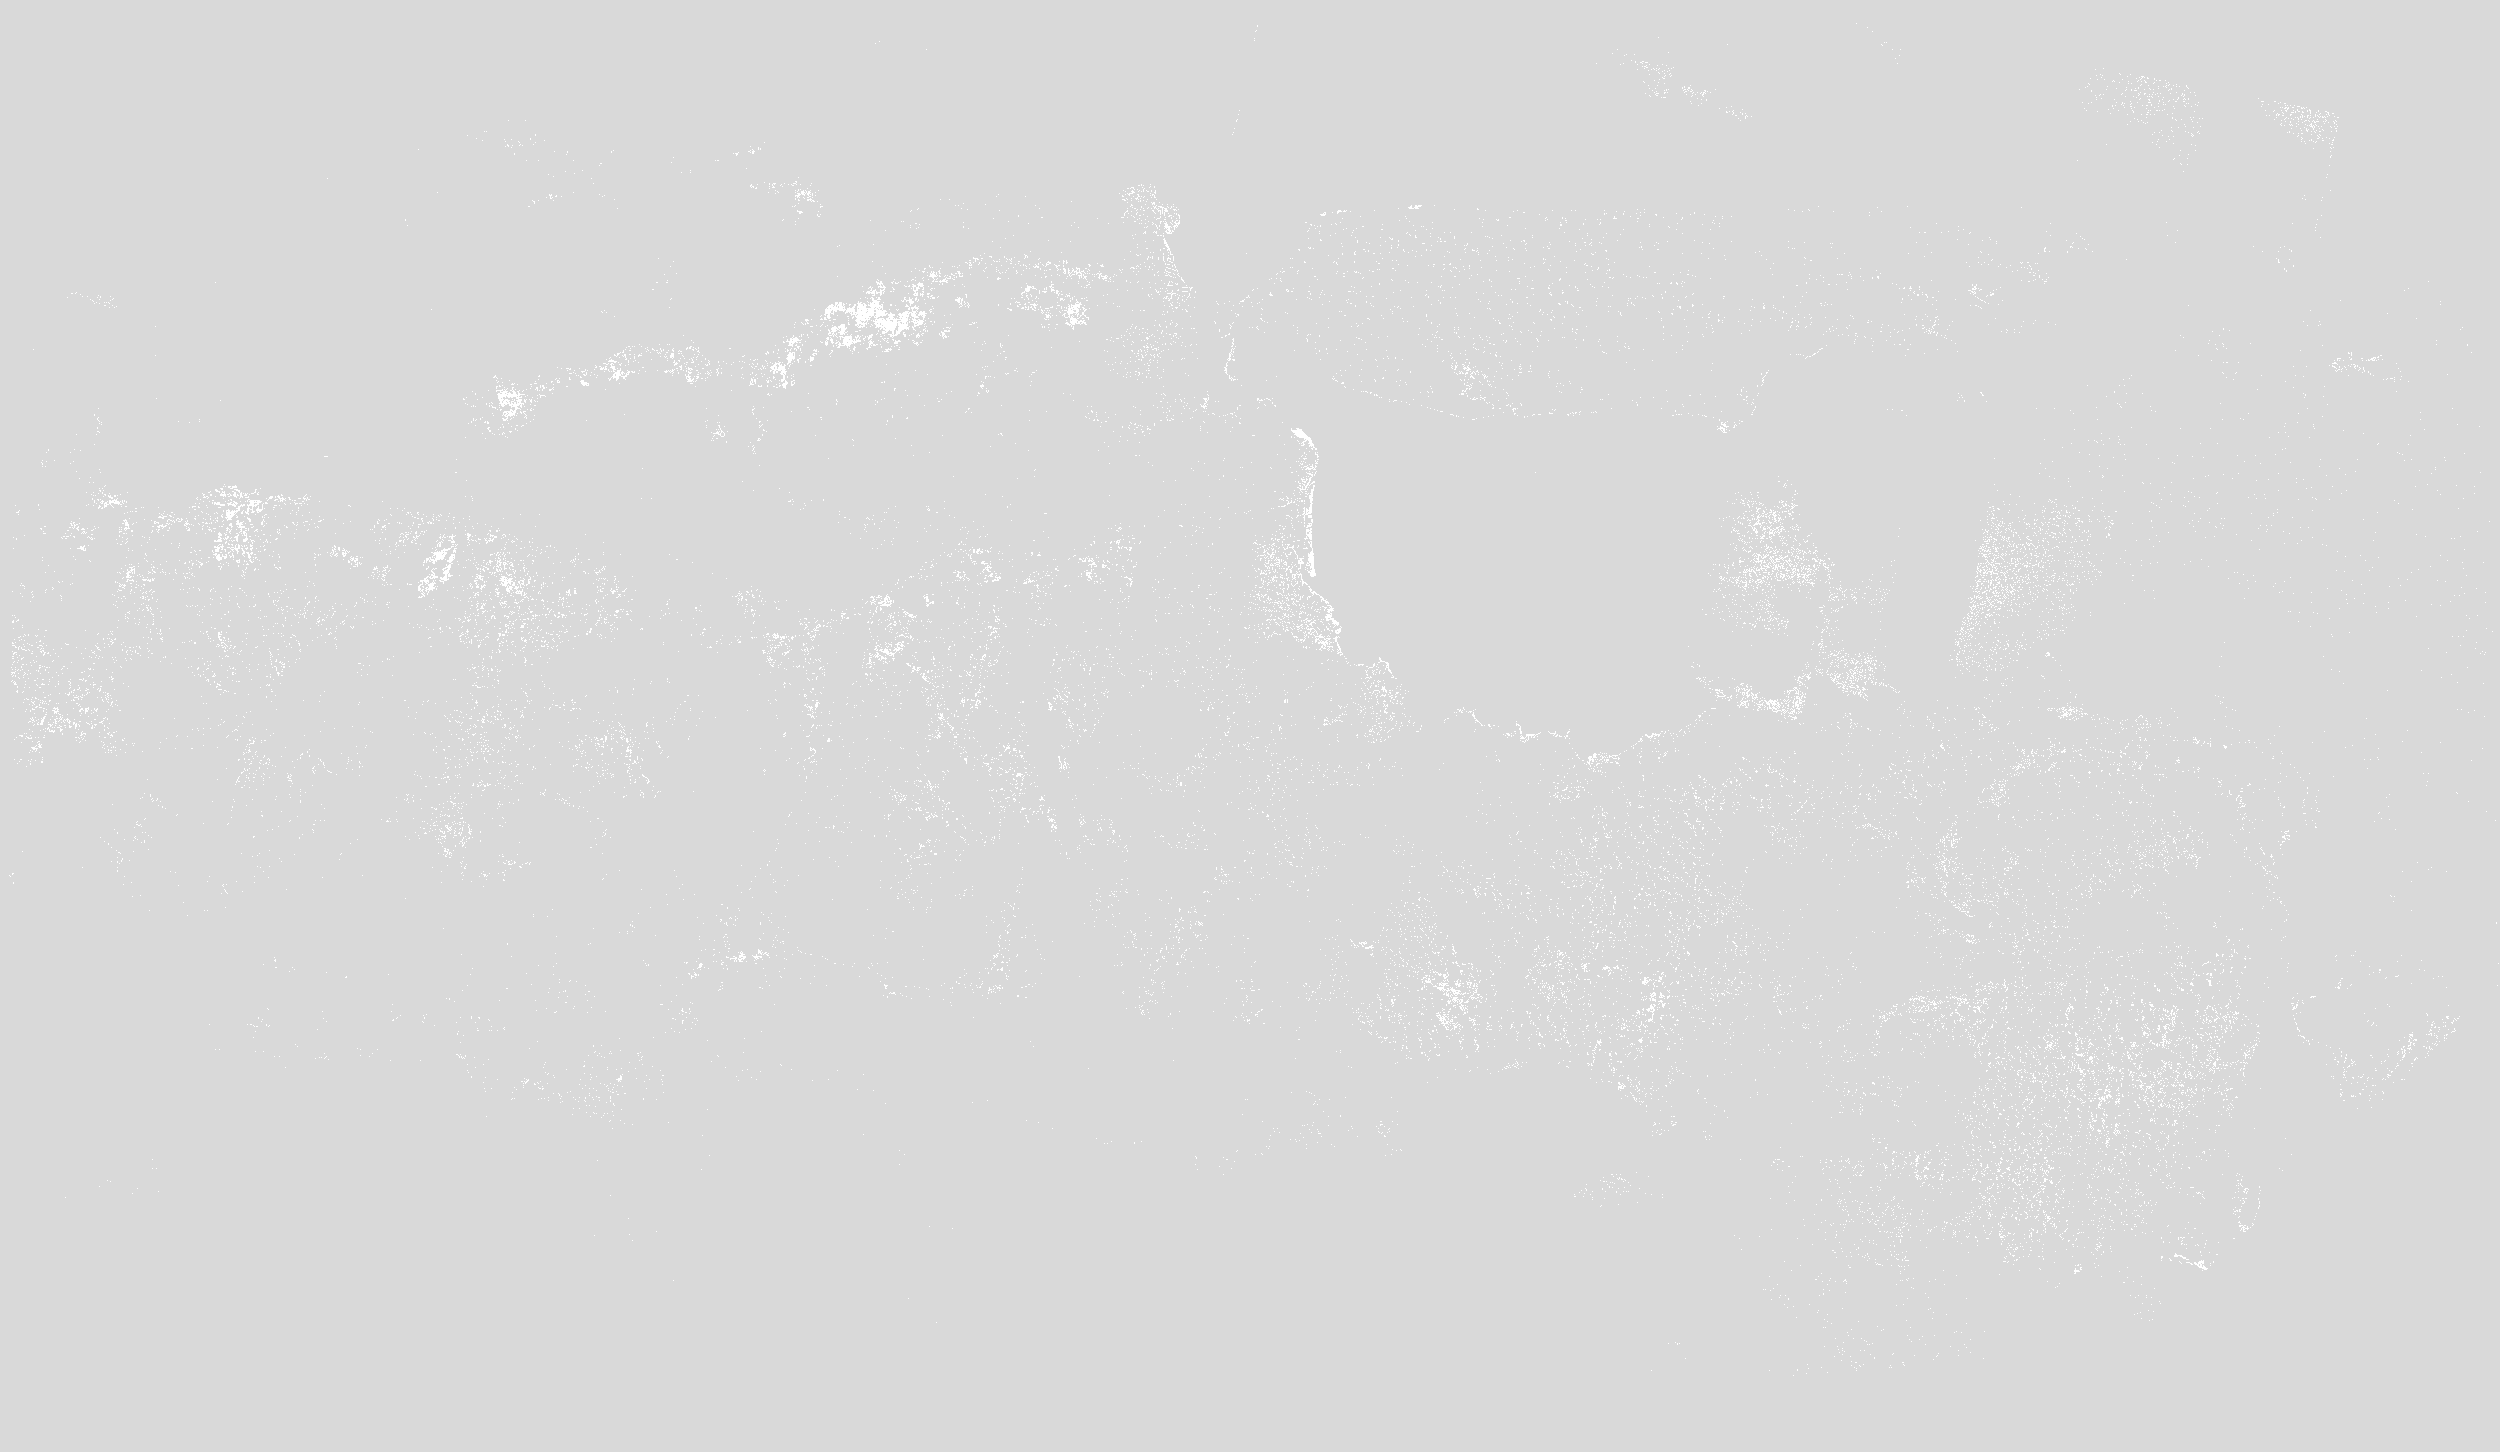

In [17]:
# Peta Mangrove dan Bukan Mangrove.
import folium
from folium import raster_layers, Element
import matplotlib.colors as mcolors
import numpy as np
from pathlib import Path
from rasterio.warp import transform_bounds
from IPython.display import display
print("Membangun peta perbandingan Mangrove dan Bukan Mangrove...")
# Periksa ketersediaan hasil klasifikasi.
required_vars = ["prediction_map", "class_to_id", "ref_crs", "bounds",
                 "height", "width", "OUTPUT_DIR"]
missing_vars = [v for v in required_vars if v not in globals()]
if missing_vars:
    raise NameError(
        "Variabel berikut belum tersedia: "
        + ", ".join(missing_vars)
        + ". Jalankan sel klasifikasi raster terlebih dahulu."
    )
# Tetapkan warna dua kategori.
COLORS_MANGROVE = {
    "Mangrove": "#17a6a1",
    "Bukan Mangrove": "#d9d9d9",
}
# Gabungkan kelas menjadi Mangrove dan Bukan Mangrove.
mangrove_id = class_to_id["Mangrove"]
mask_mangrove = prediction_map == mangrove_id
mask_bukan_mangrove = (prediction_map != mangrove_id) & (prediction_map >= 0)
# Tentukan batas dan pusat peta.
bounds_latlon = transform_bounds(
    ref_crs, "EPSG:4326", *bounds
)
bounds_peta = [
    [bounds_latlon[1], bounds_latlon[0]],
    [bounds_latlon[3], bounds_latlon[2]],
]
pusat_peta = [
    (bounds_peta[0][0] + bounds_peta[1][0]) / 2,
    (bounds_peta[0][1] + bounds_peta[1][1]) / 2,
]
m_mangrove = folium.Map(
    location=pusat_peta,
    zoom_start=8,
    tiles="OpenStreetMap"
)
# Buat dua layer peta.
mask_kategori = {
    "Mangrove": mask_mangrove,
    "Bukan Mangrove": mask_bukan_mangrove,
}
for nama_kelas, mask in mask_kategori.items():
    if not np.any(mask):
        print(f"Tidak ada piksel untuk kategori {nama_kelas}.")
        continue
    img_rgba = np.zeros((height, width, 4), dtype=np.uint8)
    r, g, b = mcolors.to_rgb(COLORS_MANGROVE[nama_kelas])
    img_rgba[mask, 0] = int(r * 255)
    img_rgba[mask, 1] = int(g * 255)
    img_rgba[mask, 2] = int(b * 255)
    img_rgba[mask, 3] = 255
    layer = folium.FeatureGroup(
        name=nama_kelas,
        overlay=True,
        control=True,
        show=True
    )
    raster_layers.ImageOverlay(
        image=img_rgba,
        bounds=bounds_peta,
        opacity=0.7,
        interactive=False,
        cross_origin=False
    ).add_to(layer)
    layer.add_to(m_mangrove)
# Tambahkan kontrol layer.
folium.LayerControl(collapsed=False).add_to(m_mangrove)
# Tambahkan pengatur transparansi.
slider_html = """
<div style="position:fixed; top:120px; left:20px; z-index:9999;
            background:white; padding:10px; border-radius:8px;
            box-shadow:2px 2px 6px rgba(0,0,0,0.3); font-family:Arial;">
    <h4 style="margin:0 0 5px 0; font-size:14px;">
        Mangrove vs Bukan Mangrove
    </h4>
    <label style="font-size:12px;">Transparansi</label><br>
    <input type="range" min="0" max="1" step="0.1" value="0.7"
           oninput="aturTransparansiMangrove(this.value)"
           style="width:180px; margin-top:5px;">
</div>
<script>
function aturTransparansiMangrove(nilai) {
    document.querySelectorAll('.leaflet-image-layer').forEach(function(gambar) {
        gambar.style.opacity = nilai;
    });
}
</script>
"""
m_mangrove.get_root().html.add_child(Element(slider_html))
# Simpan peta sebagai HTML.
nama_file_mangrove = (
    Path(OUTPUT_DIR) / "peta_mangrove_vs_bukan_mangrove.html"
)
nama_file_mangrove.parent.mkdir(parents=True, exist_ok=True)
m_mangrove.save(str(nama_file_mangrove))
print("Peta berhasil disimpan:", nama_file_mangrove)
print("Piksel Mangrove:", int(np.sum(mask_mangrove)))
print("Piksel Bukan Mangrove:", int(np.sum(mask_bukan_mangrove)))
display(m_mangrove)

## Catatan kualitas hasil

- Terdapat 70 sampel per kelas, tetapi jumlah seimbang belum tentu mewakili seluruh variasi lokasi dan kondisi spektral.
- Pembagian 80:20 memberi evaluasi awal. Gunakan sampel validasi independen untuk menilai generalisasi.
- Evaluasi Mangrove perlu memperhatikan precision, recall, F1, dan kesalahan dengan kelas Hutan.
- MVI dan REMI mendukung identifikasi mangrove, tetapi tidak menentukan kelas secara otomatis.
- Penyebut REMI yang mendekati nol ditangani sebagai NaN. Sampel dengan fitur tidak valid dikeluarkan pada tahap pembersihan.
- Awan, bayangan, pasang surut, perbedaan tanggal citra, dan skala reflektansi dapat memengaruhi hasil.
- Pastikan skala reflektansi sesuai sebelum menggunakan EVI dengan konstanta `+1`.


HASIL EVALUASI KLASIFIKASI TUTUPAN LAHAN


,Model,Accuracy (%),Macro F1 (%),Weighted F1 (%)
0,Random Forest,74.29,74.71,74.71
1,SVM,71.43,71.87,71.87
2,Decision Tree,61.43,62.17,62.17



MODEL DENGAN AKURASI TERTINGGI
Nama model: Random Forest
Akurasi: 74.29%
Macro F1: 74.71%
Weighted F1: 74.71%

LAPORAN KLASIFIKASI: Random Forest
                 precision    recall  f1-score   support

          Hutan       0.58      0.79      0.67        14
       Perairan       0.79      0.79      0.79        14
Lahan pertanian       0.69      0.79      0.73        14
       Bangunan       0.91      0.71      0.80        14
       Mangrove       0.90      0.64      0.75        14

       accuracy                           0.74        70
      macro avg       0.77      0.74      0.75        70
   weighted avg       0.77      0.74      0.75        70



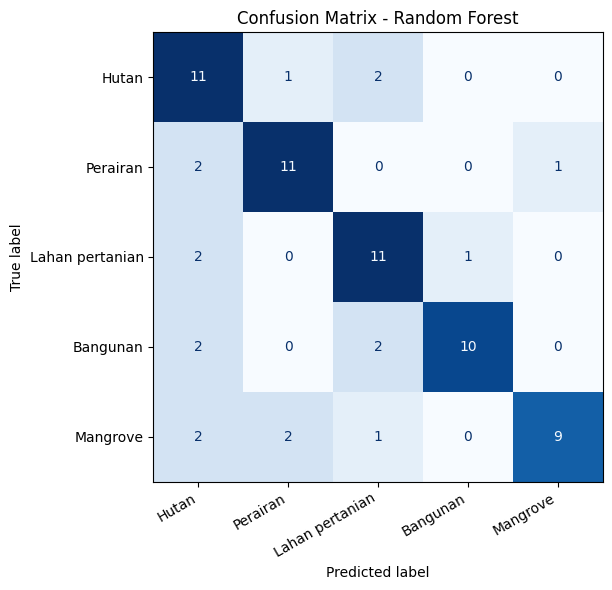

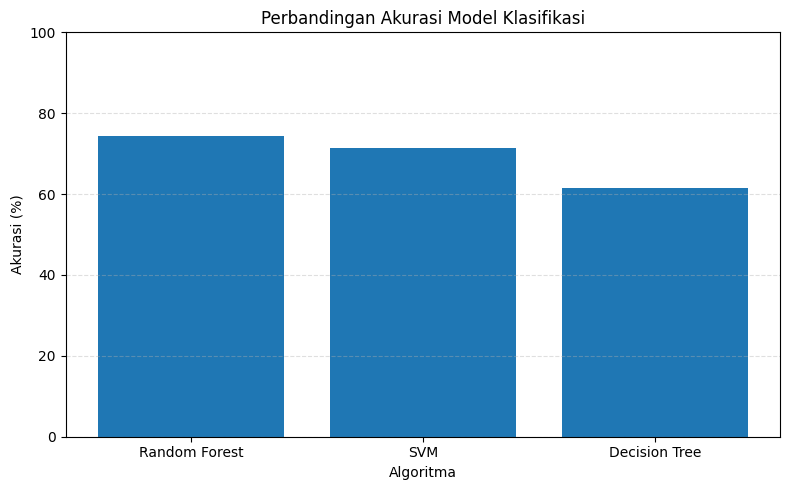

In [18]:
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import pandas as pd
import matplotlib.pyplot as plt
# Periksa hasil pelatihan.
if "fitted_models" not in globals() or "predictions" not in globals():
    raise NameError(
        "Hasil pelatihan belum tersedia. Jalankan sel pelatihan model terlebih dahulu."
    )
# Hitung metrik dari data pengujian.
hasil_evaluasi = []
for nama_model, model in fitted_models.items():
    y_pred = predictions[nama_model]
    hasil_evaluasi.append({
        "Model": nama_model,
        "Accuracy (%)": accuracy_score(y_test, y_pred) * 100,
        "Macro F1 (%)": f1_score(
            y_test, y_pred, average="macro", zero_division=0
        ) * 100,
        "Weighted F1 (%)": f1_score(
            y_test, y_pred, average="weighted", zero_division=0
        ) * 100
    })
# Bandingkan performa model.
results_df = pd.DataFrame(hasil_evaluasi)
results_df = results_df.sort_values(
    "Accuracy (%)", ascending=False
).reset_index(drop=True)
print("HASIL EVALUASI KLASIFIKASI TUTUPAN LAHAN")
display(results_df.round(2))
# Pilih model dengan akurasi tertinggi.
nama_terbaik = results_df.iloc[0]["Model"]
model_terbaik = fitted_models[nama_terbaik]
prediksi_terbaik = predictions[nama_terbaik]
print("\nMODEL DENGAN AKURASI TERTINGGI")
print("Nama model:", nama_terbaik)
print(f"Akurasi: {results_df.iloc[0]['Accuracy (%)']:.2f}%")
print(f"Macro F1: {results_df.iloc[0]['Macro F1 (%)']:.2f}%")
print(f"Weighted F1: {results_df.iloc[0]['Weighted F1 (%)']:.2f}%")
# Tampilkan metrik setiap kelas.
urutan_kelas = [
    "Hutan",
    "Perairan",
    "Lahan pertanian",
    "Bangunan",
    "Mangrove"
]
print(f"\nLAPORAN KLASIFIKASI: {nama_terbaik}")
print(classification_report(
    y_test,
    prediksi_terbaik,
    labels=urutan_kelas,
    zero_division=0
))
# Tampilkan confusion matrix model terpilih.
cm = confusion_matrix(
    y_test,
    prediksi_terbaik,
    labels=urutan_kelas
)
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=urutan_kelas
)
fig, ax = plt.subplots(figsize=(8, 6))
disp.plot(ax=ax, cmap="Blues", values_format="d", colorbar=False)
ax.set_title(f"Confusion Matrix - {nama_terbaik}")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()
# Bandingkan akurasi model dalam grafik.
plt.figure(figsize=(8, 5))
plt.bar(results_df["Model"], results_df["Accuracy (%)"])
plt.ylabel("Akurasi (%)")
plt.xlabel("Algoritma")
plt.title("Perbandingan Akurasi Model Klasifikasi")
plt.ylim(0, 100)
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()